# Taller 2 · Diseño desde el modelo

**Control Inteligente II (168418) · Universidad de Pamplona · Ing. Jeisson Martínez Flórez**

En el Lab 1 cada grupo sacó el modelo de sus dos motores. En este taller ese modelo se usa para diseñar, y no por prueba y error, las dos piezas de la cascada:

| Parte | Qué se diseña | Con qué |
|---|---|---|
| 1 | Revisión del JSON del Lab 1 | `parametros_motor_G<n>.json` |
| A | El lazo de RPM de cada rueda: prealimentación + PI por cancelación de polo | K_m, N₀, τ y L de cada motor |
| B | El lazo de equilibrio con la rueda como fuente de velocidad: planta con entrada α, polo inestable y ganancias [Kθ, Kω, Kv, Kx] por ubicación de polos | Las constantes A, B y C de la guía de modelado |

**Nombres.** En este taller la recta del motor se escribe **RPM ≈ K_m·PWM − N₀**. K_m y N₀ son la K y la B del Lab 1. Se cambian de nombre para que no se confundan con la constante **B** del modelo del balancín ni con el vector de ganancias **K**. Las claves del JSON no cambian.

**Cómo se usa.** En la celda 0 cambie `GRUPO`, las rutas y la geometría de su robot, y ejecute todo (*Run All*). Lo que viene con el repositorio es un **ejemplo sintético**, que sirve para probar el notebook. **No son medidas de un robot real.**

## 0. Configuración

In [2]:
from pathlib import Path
from collections import deque
import json

import numpy as np
import matplotlib.pyplot as plt

# ---- Lo que cambia cada grupo ----
GRUPO = "profesor_v2"                                                # p. ej. "G3"
RUTA_JSON = Path("../resultados/parametros_motor_Profesor_v2.json")  # el JSON del Lab 1
RUTA_LAZO = Path("../datos/ejemplo_sintetico_lazo")              # carpeta con los CSV o el log del programa control_rpm
RUTA_LAZO_CONFIG = Path("../src/lazo_config.h")         # aquí se escribe el diseño para el sketch

# Geometría del robot [SI]. Estos son los números del prototipo de la guía de modelado.
# Reemplácelos por los que midieron. Si no midieron I_b, use estimar_Ib() de la sección B.
GEOMETRIA = {
    "m_w": 0.030,     # masa de UNA rueda [kg]
    "r": 0.034,       # radio de la rueda [m]
    "M_b": 0.600,     # masa del cuerpo, con placas y batería [kg]
    "l": 0.070,       # distancia del eje al centro de masa del cuerpo [m]
    "I_b": 1.0e-3,    # inercia del cuerpo respecto a su centro de masa [kg·m²]
}

# ---- Diseño (se cambian en el taller) ----
LAMBDA_S = 0.050          # λ del lazo de RPM: constante de tiempo deseada en lazo cerrado
POLOS = [-6.0, -6.5, -1.5, -2.0]   # polos deseados del lazo de equilibrio [rad/s]

# ---- Fijos (iguales al sketch) ----
TS = 0.005                # periodo de los lazos: 5 ms
VENTANA = 0.010           # ventana de medición de la RPM: 10 ms
R_SUAVE = 1.0             # [RPM] el término N0 crece desde 0 hasta esta |consigna|
I_MAX = 255.0             # tope del integrador [PWM]
PWM_MAX = 255
G = 9.81

AZUL, NARANJA, VERDE_AGUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "axes.grid": True, "grid.color": "#e3e2de", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRIS,
    "axes.labelcolor": "#0b0b0b", "xtick.color": GRIS, "ytick.color": GRIS,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})
print("JSON:", RUTA_JSON, "· datos del lazo:", RUTA_LAZO)

JSON: ../resultados/parametros_motor_Profesor_v2.json · datos del lazo: ../datos/ejemplo_sintetico_lazo


## 1. Revisión del JSON del Lab 1

Antes de diseñar hay que confiar en el modelo. La tabla revisa cada número contra lo que se espera de un motorreductor de este tamaño.

- **OK** quiere decir que está en el rango esperado.
- **REVISAR** quiere decir que no necesariamente está mal, pero hay que saber explicarlo.
- **FALTA** quiere decir que no se puede diseñar sin ese dato.

El notebook lee JSON de las dos versiones del Lab 1. Si su JSON no dice `"version": 2`, vuelva a ejecutar `ajuste_motor.ipynb` con sus mismos datos. Así el retardo se calcula sin las transiciones de freno.

In [3]:
def leer_modelo(ruta):
    """Lee el JSON del Lab 1 (versión 1 o 2) y lo deja con los nombres del taller: K_m y N0."""
    d = json.loads(Path(ruta).read_text(encoding="utf-8"))
    modelo = {}
    for lado, m in d["motores"].items():
        ad = (m.get("K_adelante"), m.get("B_adelante_rpm"), m.get("zona_muerta_adelante_pwm"))
        at = (m.get("K_atras"), m.get("B_atras_rpm"), m.get("zona_muerta_atras_pwm"))
        modelo[lado] = {
            "ad": ad, "at": at,
            "tau": m.get("tau_s"), "L": m.get("retardo_s"),
            "tau_f": m.get("tau_freno_s") or m.get("tau_s"),
            "L_f": m.get("retardo_freno_s", m.get("retardo_s")),
            "cpv": m.get("cuentas_vuelta"),
            "K_inc_ad": m.get("K_incremental_girando_adelante", m.get("K_incremental_girando")),
            "K_inc_at": m.get("K_incremental_girando_atras"),
        }
    return d, modelo


datos_json, MODELO = leer_modelo(RUTA_JSON)
version = datos_json.get("version", 1)
bateria = datos_json.get("bateria_V", [0])


def fila(nombre, estado, detalle):
    print(f"  {nombre:34} {estado:8} {detalle}")


print(f"Grupo {datos_json.get('grupo')} · fecha {datos_json.get('fecha')} · versión {version} · batería {bateria} V\n")
fila("Versión del JSON", "OK" if version >= 2 else "REVISAR",
     "" if version >= 2 else "vuelva a ejecutar ajuste_motor.ipynb (retardo sin freno)")
fila("Batería anotada", "OK" if all(b > 0 for b in bateria) else "REVISAR", f"{bateria} V")
listo = True
for lado, m in MODELO.items():
    print(f"\nRueda {lado}")
    for nombre_s, (K, N0, zm) in (("adelante", m["ad"]), ("atrás", m["at"])):
        if K is None:
            fila(f"Recta {nombre_s}", "FALTA", "sin escalera en ese sentido")
            listo = False
            continue
        rpm_max = K * 255 - N0
        fila(f"Recta {nombre_s}: K_m, N0", "OK" if 20 < rpm_max < 1000 and N0 > 0 else "REVISAR",
             f"RPM = {K:.3f}·PWM − {N0:.2f} (máx. {rpm_max:.0f} RPM)")
        fila(f"Zona muerta {nombre_s}", "OK" if zm and 10 <= zm <= 35 else "REVISAR",
             f"{zm} PWM; la recta corta en N0/K_m = {N0 / K:.1f} PWM")
    if m["ad"][0] and m["at"][0]:
        asim = 100 * (m["at"][0] - m["ad"][0]) / m["ad"][0]
        fila("Asimetría de K_m (atrás/adelante)", "OK" if abs(asim) < 10 else "REVISAR", f"{asim:+.1f} %")
    for clave_inc, K, nombre_s in (("K_inc_ad", m["ad"][0], "adelante"), ("K_inc_at", m["at"][0], "atrás")):
        if m[clave_inc] and K:
            dif = 100 * (m[clave_inc] - K) / K
            fila(f"K incremental {nombre_s}", "OK" if abs(dif) <= 5 else "REVISAR", f"{dif:+.1f} % frente a la recta")
    if m["tau"] is None:
        fila("τ", "FALTA", "sin escalones")
        listo = False
        continue
    fila("τ", "OK" if 0.010 <= m["tau"] <= 0.060 else "REVISAR", f"{m['tau']*1e3:.1f} ms")
    fila("τ de freno menor que τ", "OK" if m["tau_f"] < m["tau"] else "REVISAR", f"{m['tau_f']*1e3:.1f} ms")
    fila("Retardo L", "OK" if 0 <= m["L"] <= 0.010 else "REVISAR", f"{m['L']*1e3:.1f} ms")
    fila("Cuentas por vuelta", "REVISAR" if m["cpv"] in (None, 1, 2618.0) else "OK",
         f"{m['cpv']}" + (" (¿es la del robot del docente?)" if m["cpv"] == 2618.0 else ""))
print("\n" + ("Listo para diseñar." if listo else "Falta información: complete el Lab 1 antes de seguir."))

Grupo Profesor_v2 · fecha 2026-11-10 · versión 2 · batería [7.57] V

  Versión del JSON                   OK       
  Batería anotada                    OK       [7.57] V

Rueda L
  Recta adelante: K_m, N0            OK       RPM = 0.256·PWM − 2.96 (máx. 62 RPM)
  Zona muerta adelante               OK       15 PWM; la recta corta en N0/K_m = 11.5 PWM
  Recta atrás: K_m, N0               OK       RPM = 0.246·PWM − 1.92 (máx. 61 RPM)
  Zona muerta atrás                  OK       15 PWM; la recta corta en N0/K_m = 7.8 PWM
  Asimetría de K_m (atrás/adelante)  OK       -4.2 %
  K incremental adelante             OK       +0.8 % frente a la recta
  K incremental atrás                OK       +3.2 % frente a la recta
  τ                                  OK       22.2 ms
  τ de freno menor que τ             OK       13.2 ms
  Retardo L                          OK       0.0 ms
  Cuentas por vuelta                 OK       2499.7

Rueda R
  Recta adelante: K_m, N0            REVISAR  RPM = 0.095

## A. El lazo de RPM desde el modelo

### A.1 La estructura

Cada rueda tiene su propio lazo, que corre cada **Ts = 5 ms**:

$$u = u_{ff} + K_p\,e + I, \qquad e = r - y, \qquad I \leftarrow I + K_i\,e\,T_s$$

- **r** es la consigna de RPM e **y** es la RPM medida con las cuentas de los últimos 10 ms (la ventana).
- **Prealimentación (u_ff):** es la inversa de la recta del sentido de la consigna:

$$u_{ff} = \text{signo}(r)\,\frac{|r| + N_0\,s}{K_m}, \qquad s = \min\left(1, \frac{|r|}{1\ \text{RPM}}\right)$$

  El término $N_0/K_m$ es la **compensación de la zona muerta**. Es el PWM donde la recta corta el eje, y se suaviza con $s$ cerca de 0 para que una consigna que cruza el cero no dé golpes de ±N₀/K_m. La prealimentación pone casi todo el mando de una vez, y el PI solo corrige la diferencia.
- **PI por cancelación de polo:** el cero del PI cancela el polo del motor.

$$T_i = \tau, \qquad K_p = \frac{\tau}{K_m(\lambda + L_{total})}, \qquad K_i = \frac{K_p}{\tau}, \qquad L_{total} = L + \frac{T_s}{2} + \frac{\text{ventana}}{2}$$

- **Integración condicional:** si el mando ya está saturado (±255) y el error empuja hacia el mismo lado, el integrador no se actualiza. Así se evita el *windup*.
- **Consigna 0:** PWM 0 (freno en corto) e integrador en cero.
- **Criterio de K:** por sentido. Con consigna positiva se usan K_m y N₀ de adelante, y con negativa los de atrás. La versión promediada queda para comparar.

Es importante tener en cuenta por qué N₀/K_m no es la zona muerta medida. N₀/K_m es el PWM donde la recta, extendida hacia abajo, llega a 0 RPM. La rueda real se detiene antes, porque por debajo de la zona muerta no gira de forma sostenida. Entre N₀/K_m y la zona muerta queda un hueco que la recta no explica, y ese hueco lo llena el integrador. Si uno compensa la zona muerta completa, el mando salta de +zona muerta a −zona muerta cada vez que la consigna cruza el cero, y el motor vibra.

In [4]:
def recta(m, signo, criterio="por_sentido"):
    """(K_m, N0, zona muerta) para una consigna de ese signo."""
    if criterio == "promediada":
        return tuple(float(np.mean([m["ad"][i], m["at"][i]])) for i in range(3))
    return m["ad"] if signo >= 0 else m["at"]


def l_total(m):
    return m["L"] + TS / 2 + VENTANA / 2


def disenar_pi(m, lam=LAMBDA_S, criterio="por_sentido"):
    """Kp y Ki para consigna positiva [0] y negativa [1]."""
    kp = [m["tau"] / (recta(m, s, criterio)[0] * (lam + l_total(m))) for s in (+1, -1)]
    return kp, [k / m["tau"] for k in kp]


print(f"λ = {LAMBDA_S*1e3:.0f} ms, Ts = {TS*1e3:.0f} ms, ventana = {VENTANA*1e3:.0f} ms\n")
print(f"{'rueda':6} {'criterio':12} {'sentido':9} {'K_m':>6} {'N0':>5} {'τ [ms]':>7} {'L_tot [ms]':>10} {'Kp':>6} {'Ki':>6}")
for lado, m in MODELO.items():
    for criterio in ("por_sentido", "promediada"):
        kp, ki = disenar_pi(m, LAMBDA_S, criterio)
        for i, (sentido, s) in enumerate((("adelante", +1), ("atrás", -1))):
            K, N0, _ = recta(m, s, criterio)
            print(f"{lado:6} {criterio:12} {sentido:9} {K:6.3f} {N0:5.2f} {m['tau']*1e3:7.1f} "
                  f"{l_total(m)*1e3:10.1f} {kp[i]:6.2f} {ki[i]:6.1f}")
print("\nKp en PWM/RPM y Ki en PWM/(RPM·s). Estos son los valores que debe imprimir el sketch con el comando v.")

λ = 50 ms, Ts = 5 ms, ventana = 10 ms

rueda  criterio     sentido      K_m    N0  τ [ms] L_tot [ms]     Kp     Ki
L      por_sentido  adelante   0.256  2.96    22.2        7.5   1.51   67.8
L      por_sentido  atrás      0.246  1.92    22.2        7.5   1.57   70.8
L      promediada   adelante   0.251  2.44    22.2        7.5   1.54   69.3
L      promediada   atrás      0.251  2.44    22.2        7.5   1.54   69.3
R      por_sentido  adelante   0.095 -21.54    17.7        8.3   3.20  181.1
R      por_sentido  atrás      0.071 -58.62    17.7        8.3   4.29  242.4
R      promediada   adelante   0.083 -40.08    17.7        8.3   3.67  207.3
R      promediada   atrás      0.083 -40.08    17.7        8.3   3.67  207.3

Kp en PWM/RPM y Ki en PWM/(RPM·s). Estos son los valores que debe imprimir el sketch con el comando v.


### A.2 El diseño para el sketch

Esta celda escribe `src/lazo_config.h` con el modelo de sus motores. El sketch calcula Kp y Ki con las mismas fórmulas. Al arrancar, y con el comando `v`, el sketch los imprime, y deben coincidir con la tabla de arriba. Si no coinciden, el modelo que quedó en el sketch no es el de su JSON.

Si trabaja en Colab, copie el texto que imprime la celda en el archivo.

In [5]:
def generar_lazo_config(modelo, lam=LAMBDA_S, grupo=GRUPO):
    lineas = [
        "/*",
        " * lazo_config.h — Modelo de los motores y diseño del lazo de RPM",
        f" * Generado por el notebook del Taller 2 para el grupo {grupo}, a partir de {RUTA_JSON.name}",
        " * RPM ≈ K_m·PWM − N0, una recta por sentido. K_m = K del Lab 1, N0 = B del Lab 1.",
        " */",
        "#pragma once",
        "",
    ]
    for lado in ("L", "R"):
        m = modelo[lado]
        nombre = "izquierda" if lado == "L" else "derecha"
        lineas.append(f"// Rueda {nombre} ({lado})")
        for sufijo, (K, N0, zm) in (("ADELANTE", m["ad"]), ("ATRAS", m["at"])):
            lineas += [f"#define {'KM_' + lado + '_' + sufijo:15} {K:.5f}f",
                       f"#define {'N0_' + lado + '_' + sufijo:15} {N0:.5f}f",
                       f"#define {'ZM_' + lado + '_' + sufijo:15} {int(zm)}"]
        lineas += [f"#define {'TAU_' + lado + '_S':15} {m['tau']:.5f}f",
                   f"#define {'RETARDO_' + lado + '_S':15} {m['L']:.5f}f", ""]
    lineas += [
        "// Diseño del lazo (valores iniciales; se cambian en vivo con comandos)",
        f"#define LAMBDA_MS        {lam*1e3:.0f}",
        "#define CRITERIO_K        0     // 0 = por sentido, 1 = promediada",
        "#define PREALIMENTACION   1",
        "#define REF_TAU_MS        0     // modelo de referencia apagado",
        "",
        f"#define TS_LAZO_US       {TS*1e6:.0f}",
        f"#define VENTANA_MS         {VENTANA*1e3:.0f}",
        f"#define R_SUAVE_RPM      {R_SUAVE:.1f}f",
        f"#define I_MAX_PWM       {I_MAX:.1f}f",
        "#define REF_MAX_RPM      60.0f",
        "",
        "// Ensayo de escalón de consigna",
        "#define LAZO_ANTES_MS     500",
        "#define LAZO_DURANTE_MS  1000",
        "#define LAZO_DESPUES_MS   700",
        "",
    ]
    return "\n".join(lineas)


texto = generar_lazo_config(MODELO)
if GRUPO != "ejemplo":
    RUTA_LAZO_CONFIG.write_text(texto, encoding="utf-8")
    print("Escrito en", RUTA_LAZO_CONFIG, "\n")
else:
    print("GRUPO = 'ejemplo': no se sobrescribe el archivo del repositorio. Así quedaría:\n")
print(texto)

Escrito en ../src/lazo_config.h 

/*
 * lazo_config.h — Modelo de los motores y diseño del lazo de RPM
 * Generado por el notebook del Taller 2 para el grupo profesor_v2, a partir de parametros_motor_Profesor_v2.json
 * RPM ≈ K_m·PWM − N0, una recta por sentido. K_m = K del Lab 1, N0 = B del Lab 1.
 */
#pragma once

// Rueda izquierda (L)
#define KM_L_ADELANTE   0.25638f
#define N0_L_ADELANTE   2.96080f
#define ZM_L_ADELANTE   15
#define KM_L_ATRAS      0.24557f
#define N0_L_ATRAS      1.92022f
#define ZM_L_ATRAS      15
#define TAU_L_S         0.02222f
#define RETARDO_L_S     0.00000f

// Rueda derecha (R)
#define KM_R_ADELANTE   0.09473f
#define N0_R_ADELANTE   -21.53526f
#define ZM_R_ADELANTE   20
#define KM_R_ATRAS      0.07076f
#define N0_R_ATRAS      -58.61934f
#define ZM_R_ATRAS      20
#define TAU_R_S         0.01770f
#define RETARDO_R_S     0.00080f

// Diseño del lazo (valores iniciales; se cambian en vivo con comandos)
#define LAMBDA_MS        50
#define CRITERIO_K        0 

### A.3 El modelo en lazo cerrado

Para saber si el lazo se comporta como se diseñó, hace falta una predicción. La predicción es una simulación con el **mismo algoritmo del sketch**, línea por línea, y con el motor del Lab 1:

- el motor es un primer orden con τ, el retardo L, la recta de cada sentido, la zona muerta y la saturación en ±255;
- el encoder entrega cuentas enteras, así que la RPM medida tiene el mismo ruido de cuantización que en el robot;
- el controlador corre cada 5 ms y el motor se simula cada 0,1 ms.

Con eso se predice el escalón de 10 a 30 RPM de cada rueda.

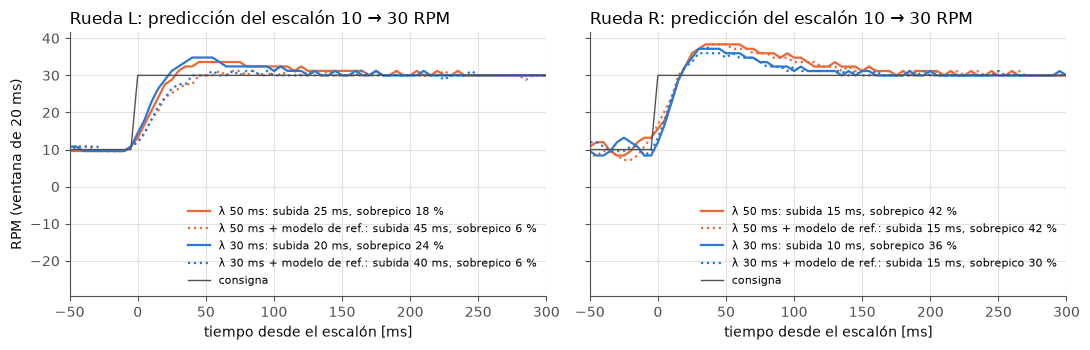

In [6]:
class LazoRPM:
    """El lazo del sketch lazo_rpm (sección 4 de main.cpp), en Python."""

    def __init__(self, m, lam=LAMBDA_S, criterio="por_sentido", ff=True, ref_tau=0.0):
        self.m, self.criterio, self.ff, self.ref_tau = m, criterio, ff, ref_tau
        self.kp, self.ki = disenar_pi(m, lam, criterio)
        self.integ = self.ref_f = 0.0

    def paso(self, r, y, dt=TS):
        if r == 0:                                   # consigna 0: freno, sin integral
            self.integ = self.ref_f = 0.0
            return 0.0
        if self.ref_tau > 0:                         # modelo de referencia (opcional)
            self.ref_f += (r - self.ref_f) * (1 - np.exp(-dt / self.ref_tau))
        else:
            self.ref_f = r
        e = self.ref_f - y
        i = 0 if r > 0 else 1
        K, N0, _ = recta(self.m, 1 if r > 0 else -1, self.criterio)
        s = min(1.0, abs(r) / R_SUAVE)
        u_ff = np.sign(r) * (abs(r) + N0 * s) / K if self.ff else 0.0
        candidato = np.clip(self.integ + self.ki[i] * e * dt, -I_MAX, I_MAX)
        crudo = u_ff + self.kp[i] * e + candidato
        if not ((crudo > PWM_MAX and e > 0) or (crudo < -PWM_MAX and e < 0)):   # integración condicional
            self.integ = candidato
        return float(np.clip(u_ff + self.kp[i] * e + self.integ, -PWM_MAX, PWM_MAX))


class MotorSim:
    """Motor del Lab 1: primer orden con retardo, recta por sentido, zona muerta y saturación."""

    def __init__(self, m, h=1e-4):
        self.m, self.h = m, h
        self.rpm = self.pos = 0.0                   # RPM y vueltas de la rueda (respecto al cuerpo)
        self.cola = deque([0.0] * max(1, int(round(m["L"] / h))))

    def paso(self, u):
        """Avanza h segundos con el PWM u. Devuelve la aceleración de la rueda [RPM/s]."""
        self.cola.append(u)
        u = self.cola.popleft()
        K, N0, zm = self.m["ad"] if u > 0 else self.m["at"]
        if u != 0 and abs(u) >= zm:
            objetivo, tau = np.sign(u) * (K * abs(u) - N0), self.m["tau"]
        else:
            objetivo, tau = 0.0, (self.m["tau_f"] if u == 0 else self.m["tau"])
        acel = (objetivo - self.rpm) / tau
        self.rpm += acel * self.h
        self.pos += self.rpm / 60 * self.h
        return acel

    def cuentas(self):
        return np.floor(self.pos * self.m["cpv"])


def simular_lazo(m, consigna, **diseno):
    """consigna: arreglo con la consigna en cada muestra de 5 ms. Devuelve t, u y cuentas."""
    lazo, motor = LazoRPM(m, **diseno), MotorSim(m)
    n_sub, n_v = int(round(TS / motor.h)), int(round(VENTANA / TS))
    cuentas, u = np.zeros(len(consigna)), np.zeros(len(consigna))
    for k, r in enumerate(consigna):
        cuentas[k] = motor.cuentas()
        y = (cuentas[k] - cuentas[k - n_v]) / m["cpv"] / (n_v * TS) * 60 if k >= n_v else 0.0
        u[k] = round(lazo.paso(r, y))
        for _ in range(n_sub):
            motor.paso(u[k])
    return np.arange(len(consigna)) * TS, u, cuentas


def rpm_de_cuentas(c, cpv, ventana=VENTANA, ts=TS):
    """RPM con una ventana centrada, a partir de las cuentas."""
    h = max(1, int(round(ventana / ts / 2)))
    rpm = np.full(len(c), np.nan)
    rpm[h:-h] = (c[2 * h:] - c[:-2 * h]) / cpv / (2 * h * ts) * 60
    return rpm


def metricas(t, rpm, r0, r1, t_ini, t_fin):
    """Subida 10–90 %, sobrepico y error en régimen del escalón r0 → r1 que va de t_ini a t_fin."""
    sel = (t >= t_ini) & (t < t_fin) & ~np.isnan(rpm)
    tt, avance = t[sel] - t_ini, (rpm[sel] - r0) / (r1 - r0)
    t10 = tt[np.argmax(avance >= 0.1)] if np.any(avance >= 0.1) else np.nan
    t90 = tt[np.argmax(avance >= 0.9)] if np.any(avance >= 0.9) else np.nan
    regimen = np.nanmean(rpm[sel][len(tt) // 2:])
    return {"subida_ms": (t90 - t10) * 1e3, "sobrepico_%": 100 * max(0.0, np.nanmax(avance) - 1),
            "error_rpm": r1 - regimen}


def escalon(r0, r1, antes=0.5, durante=1.0, despues=0.7):
    return np.concatenate([np.full(int(round(antes / TS)), r0), np.full(int(round(durante / TS)), r1),
                           np.full(int(round(despues / TS)), r0)])


fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
consigna = escalon(10, 30)
for ax, (lado, m) in zip(ejes, MODELO.items()):
    for lam, color in ((0.050, NARANJA), (0.030, AZUL)):
        for ref_tau, estilo in ((0.0, "-"), (m["tau"], ":")):
            t, u, c = simular_lazo(m, consigna, lam=lam, ref_tau=ref_tau)
            rpm = rpm_de_cuentas(c, m["cpv"], ventana=0.020)
            met = metricas(t, rpm, 10, 30, 0.5, 1.5)
            etiqueta = f"λ {lam*1e3:.0f} ms" + (" + modelo de ref." if ref_tau else "")
            ax.plot((t - 0.5) * 1e3, rpm, estilo, color=color, lw=1.6,
                    label=f"{etiqueta}: subida {met['subida_ms']:.0f} ms, sobrepico {met['sobrepico_%']:.0f} %")
    ax.plot((t - 0.5) * 1e3, consigna, color=GRIS, lw=1, label="consigna")
    ax.set_xlim(-50, 300)
    ax.set_title(f"Rueda {lado}: predicción del escalón 10 → 30 RPM", loc="left")
    ax.set_xlabel("tiempo desde el escalón [ms]")
    ax.legend(loc="lower right", fontsize=8)
ejes[0].set_ylabel("RPM (ventana de 20 ms)")
plt.tight_layout()
plt.show()

**Cómo leer la gráfica.** Con prealimentación, la subida la pone casi toda el motor, porque el PWM correcto llega de una vez. El PI suma su parte mientras el error es grande, y eso produce el sobrepico.

El **modelo de referencia** (línea punteada) compara la RPM medida contra la respuesta que se espera del motor a la prealimentación, que es la consigna filtrada con la τ del motor. Así el PI no empuja de más durante la subida. En el sketch se activa con `m` seguido de su τ en ms.

### A.4 Verificación en el robot: medida frente a modelo

En el laboratorio, con el robot en el soporte, corran el sketch `lazo_rpm` y guarden cada bloque entre `INICIO_CSV` y `FIN_CSV`, o el log completo, en `RUTA_LAZO`. La celda encuentra cada ensayo `ensayo=lazo`, lo simula con **el mismo diseño con que se corrió** (λ, criterio, prealimentación y modelo de referencia, que vienen en la línea `#`) y compara.

Si el modelo y la medida se parecen, el diseño desde el modelo funciona y se puede confiar en él para el lazo de equilibrio. Si no se parecen, la diferencia dice qué revisar.

In [6]:
def leer_descripcion(linea):
    meta = {}
    for par in linea.lstrip("#").split():
        if "=" in par:
            clave, valor = par.split("=", 1)
            try:
                meta[clave] = float(valor) if any(ch in valor for ch in ".eE") else int(valor)
            except ValueError:
                meta[clave] = valor
    return meta


def leer_ensayos_lazo(carpeta):
    """Bloques del sketch lazo_rpm: columnas t_us, rL, rR, uL, uR, cL, cR."""
    ensayos = []
    for p in sorted(Path(carpeta).glob("*")):
        if p.suffix.lower() not in (".csv", ".log", ".txt"):
            continue
        meta, filas = None, []
        for linea in p.read_text(encoding="utf-8", errors="replace").splitlines():
            linea = linea.strip()
            if linea.startswith("# ensayo="):
                meta, filas = leer_descripcion(linea), []
            elif linea == "FIN_CSV" or (linea == "INICIO_CSV" and meta and filas):
                if meta and meta.get("ensayo") == "lazo" and filas:
                    d = np.array(filas)
                    ensayos.append({"meta": meta, "origen": p.name, "t": (d[:, 0] - d[0, 0]) * 1e-6,
                                    "r": {"L": d[:, 1], "R": d[:, 2]}, "u": {"L": d[:, 3], "R": d[:, 4]},
                                    "c": {"L": d[:, 5], "R": d[:, 6]}})
                meta, filas = None, []
            elif meta and linea and linea[0].isdigit():
                partes = linea.split(",")
                if len(partes) == 7:
                    filas.append([float(x) for x in partes])
    return ensayos


ensayos_lazo = leer_ensayos_lazo(RUTA_LAZO)
print(f"{len(ensayos_lazo)} ensayos de lazo en {RUTA_LAZO}\n")
for i, e in enumerate(ensayos_lazo):
    m = e["meta"]
    print(f"{i:>2}  motor {m['motor']}  {m['base']:>6} → {m['escalon']:<6} RPM  λ {m['lambda_ms']} ms  "
          f"criterio {m['criterio']:12} ff {m['ff']}  modelo ref. {m['ref_tau_ms']} ms  batería {m['bateria_V']} V  ({e['origen']})")

7 ensayos de lazo en ../datos/ejemplo_sintetico_lazo

 0  motor A    10.0 → 30.0   RPM  λ 50 ms  criterio por_sentido  ff 1  modelo ref. 0 ms  batería 7.7 V  (lazo_ejemplo.log)
 1  motor A   -10.0 → -30.0  RPM  λ 50 ms  criterio por_sentido  ff 1  modelo ref. 0 ms  batería 7.7 V  (lazo_ejemplo.log)
 2  motor A     0.0 → 10.0   RPM  λ 50 ms  criterio por_sentido  ff 1  modelo ref. 0 ms  batería 7.7 V  (lazo_ejemplo.log)
 3  motor A    10.0 → -10.0  RPM  λ 50 ms  criterio por_sentido  ff 1  modelo ref. 0 ms  batería 7.7 V  (lazo_ejemplo.log)
 4  motor A    10.0 → -10.0  RPM  λ 50 ms  criterio promediada   ff 1  modelo ref. 0 ms  batería 7.7 V  (lazo_ejemplo.log)
 5  motor A    10.0 → 30.0   RPM  λ 50 ms  criterio por_sentido  ff 1  modelo ref. 21 ms  batería 7.7 V  (lazo_ejemplo.log)
 6  motor A    10.0 → 30.0   RPM  λ 50 ms  criterio por_sentido  ff 0  modelo ref. 0 ms  batería 7.7 V  (lazo_ejemplo.log)


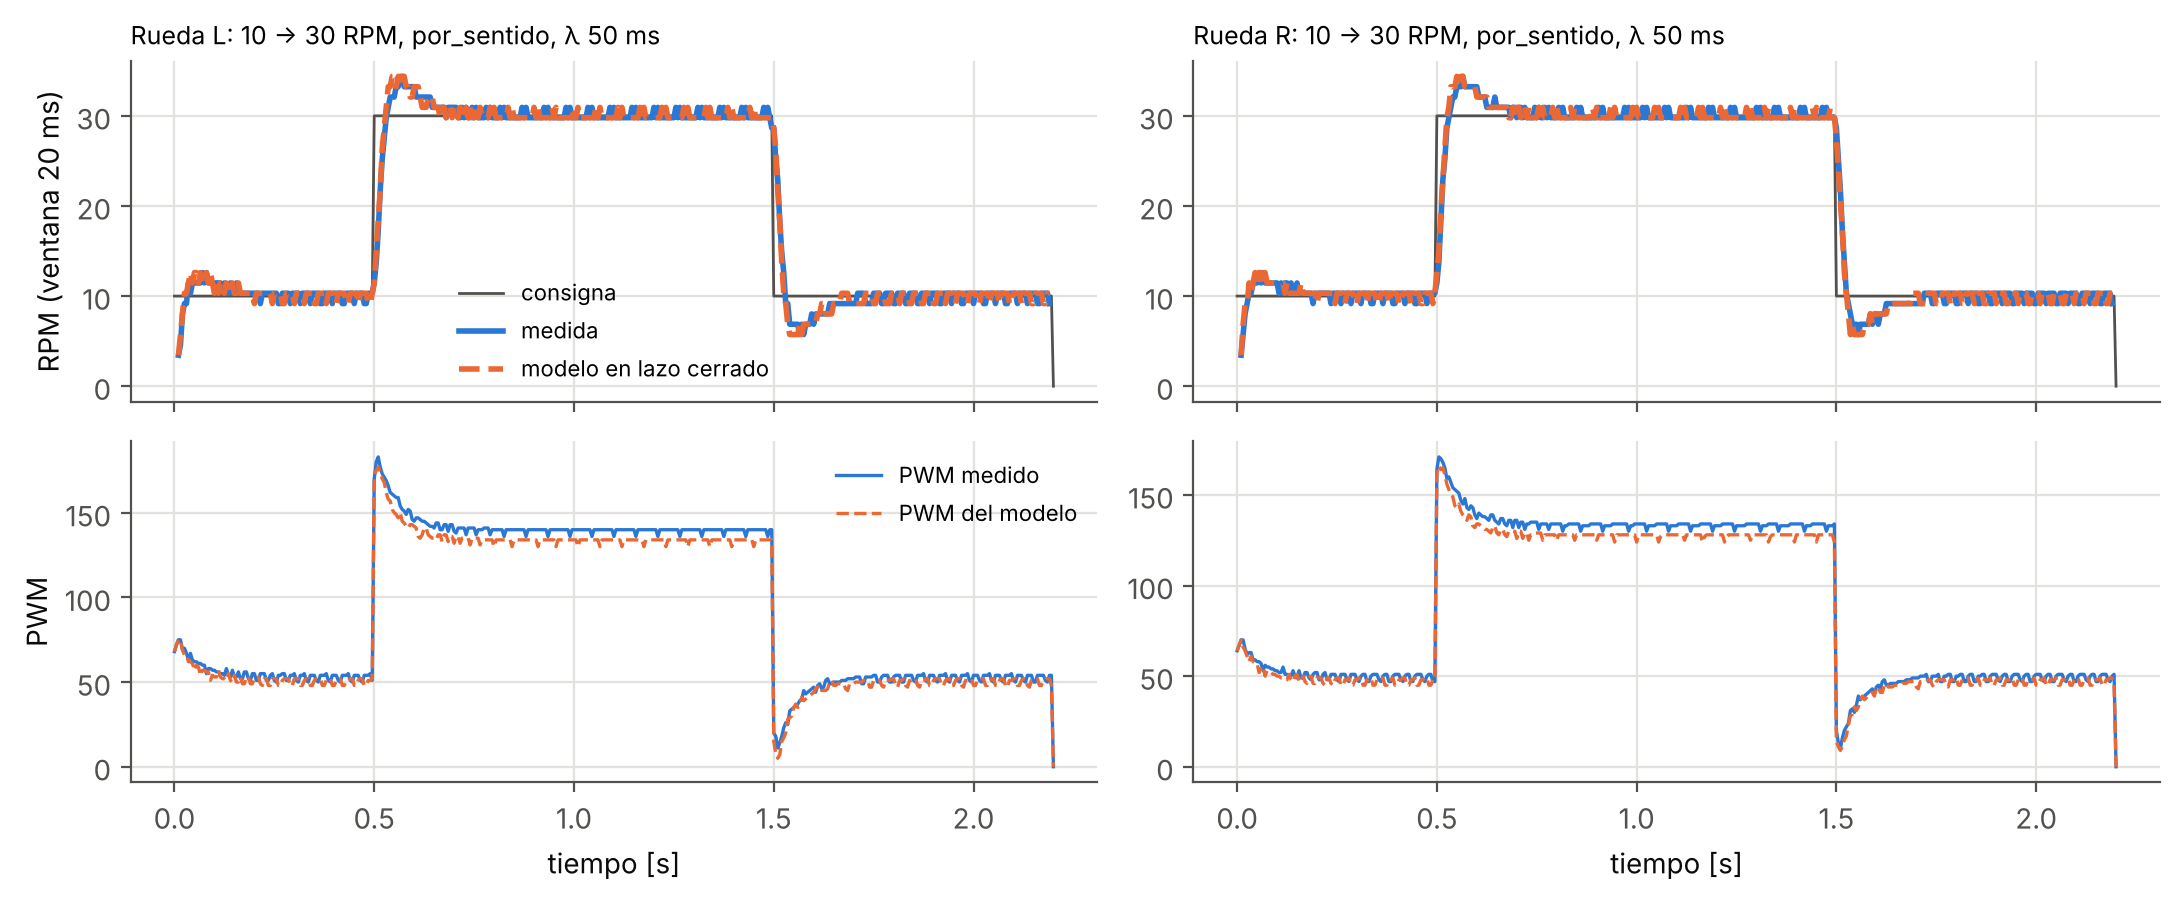

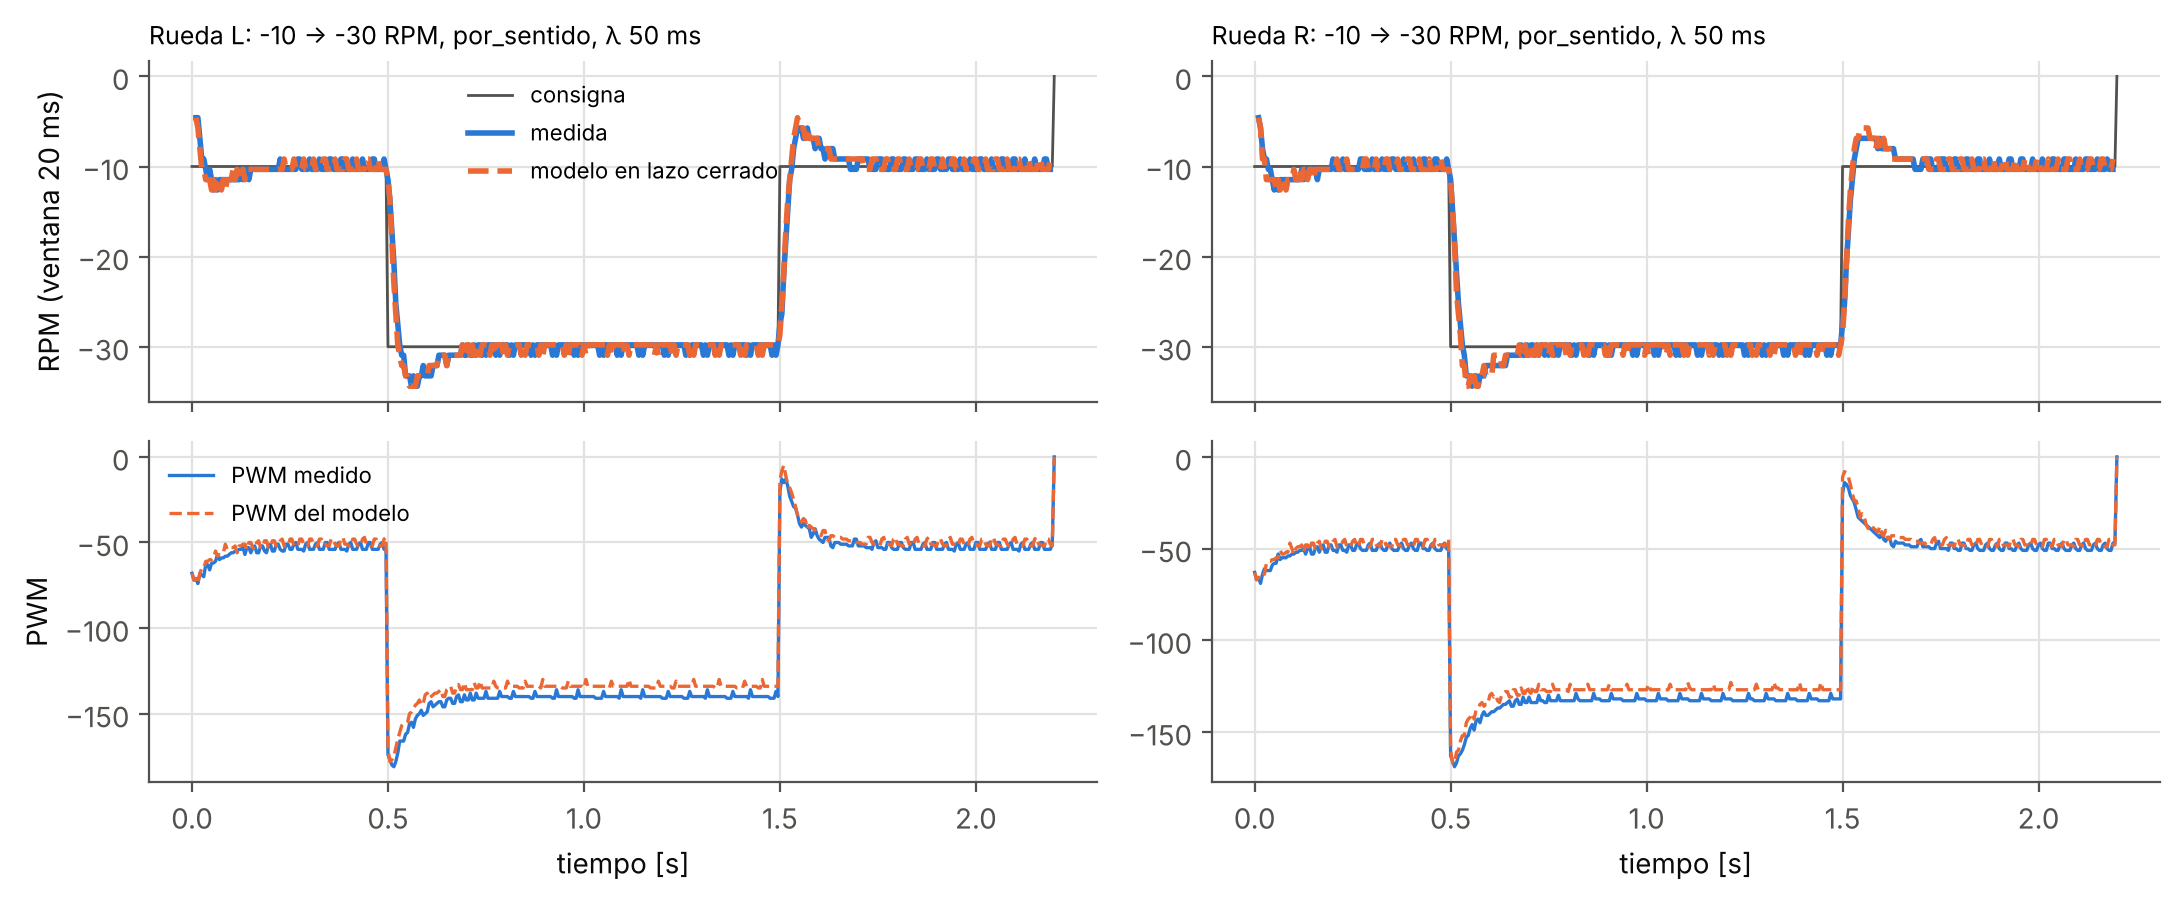

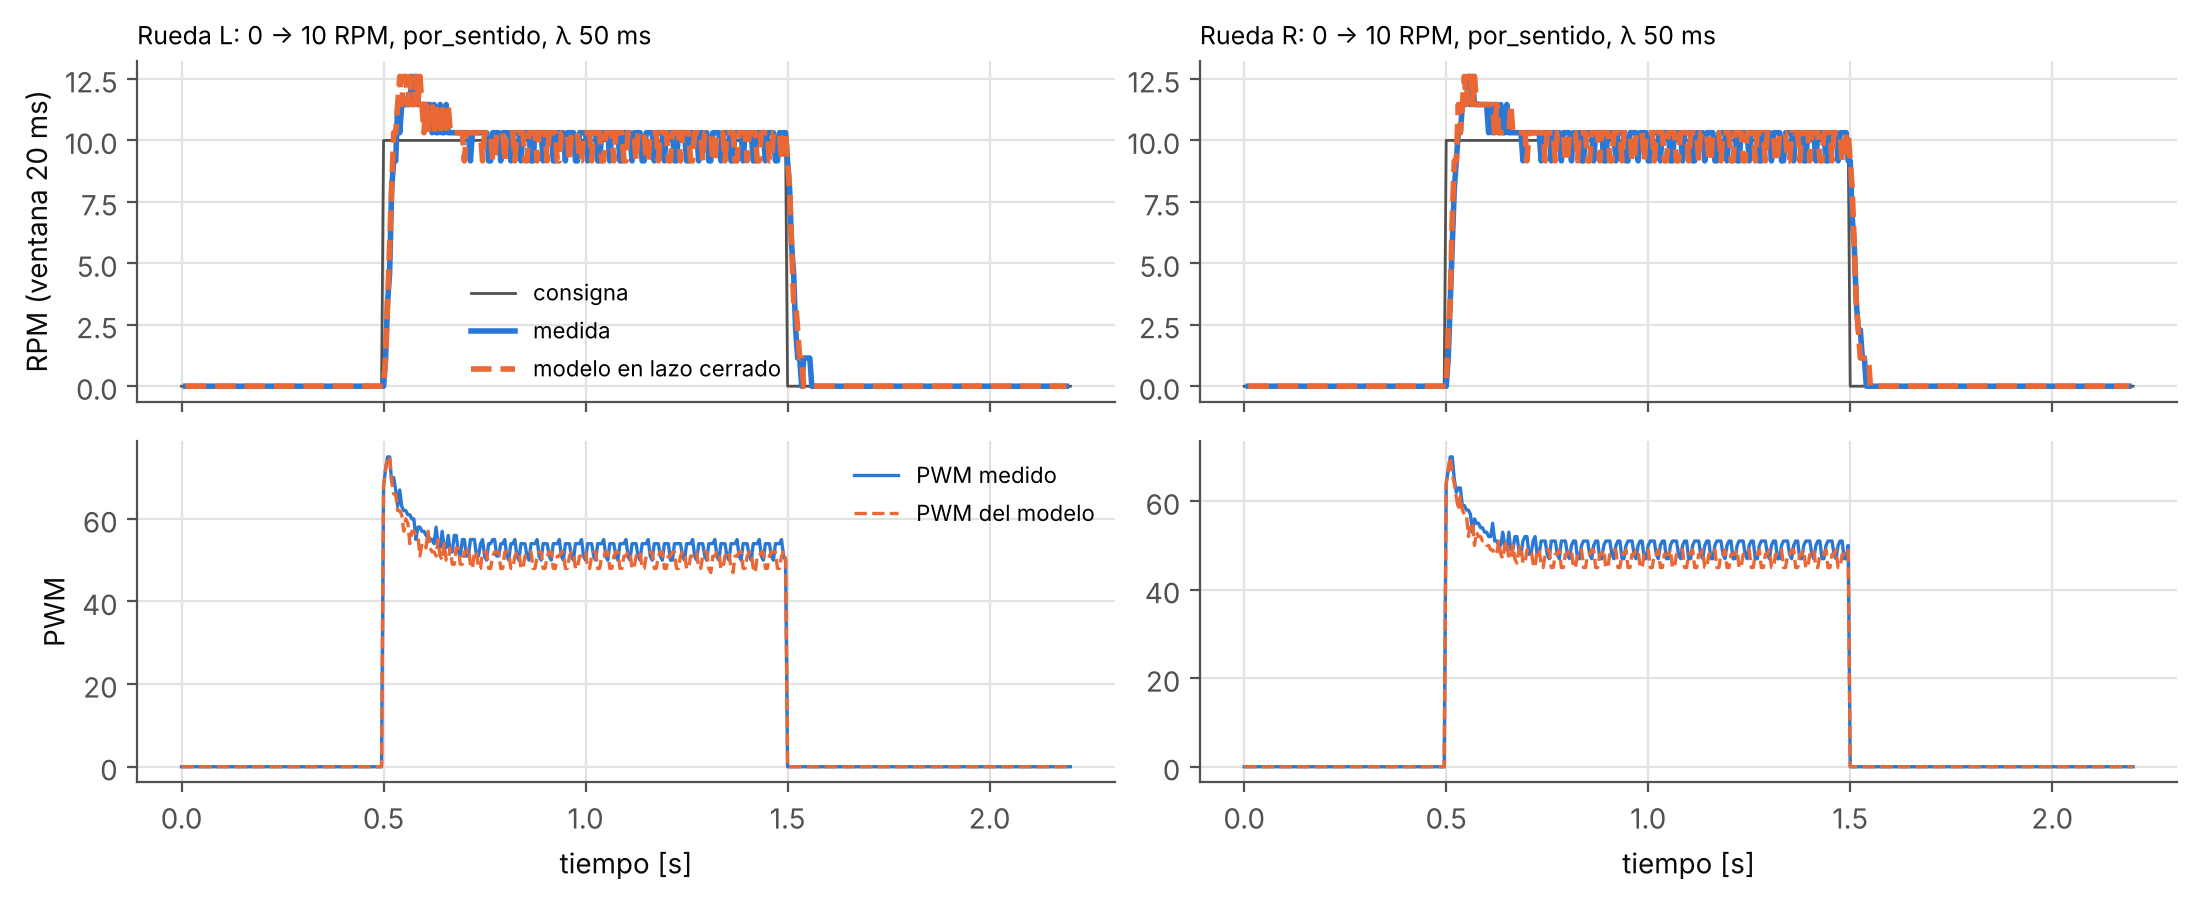

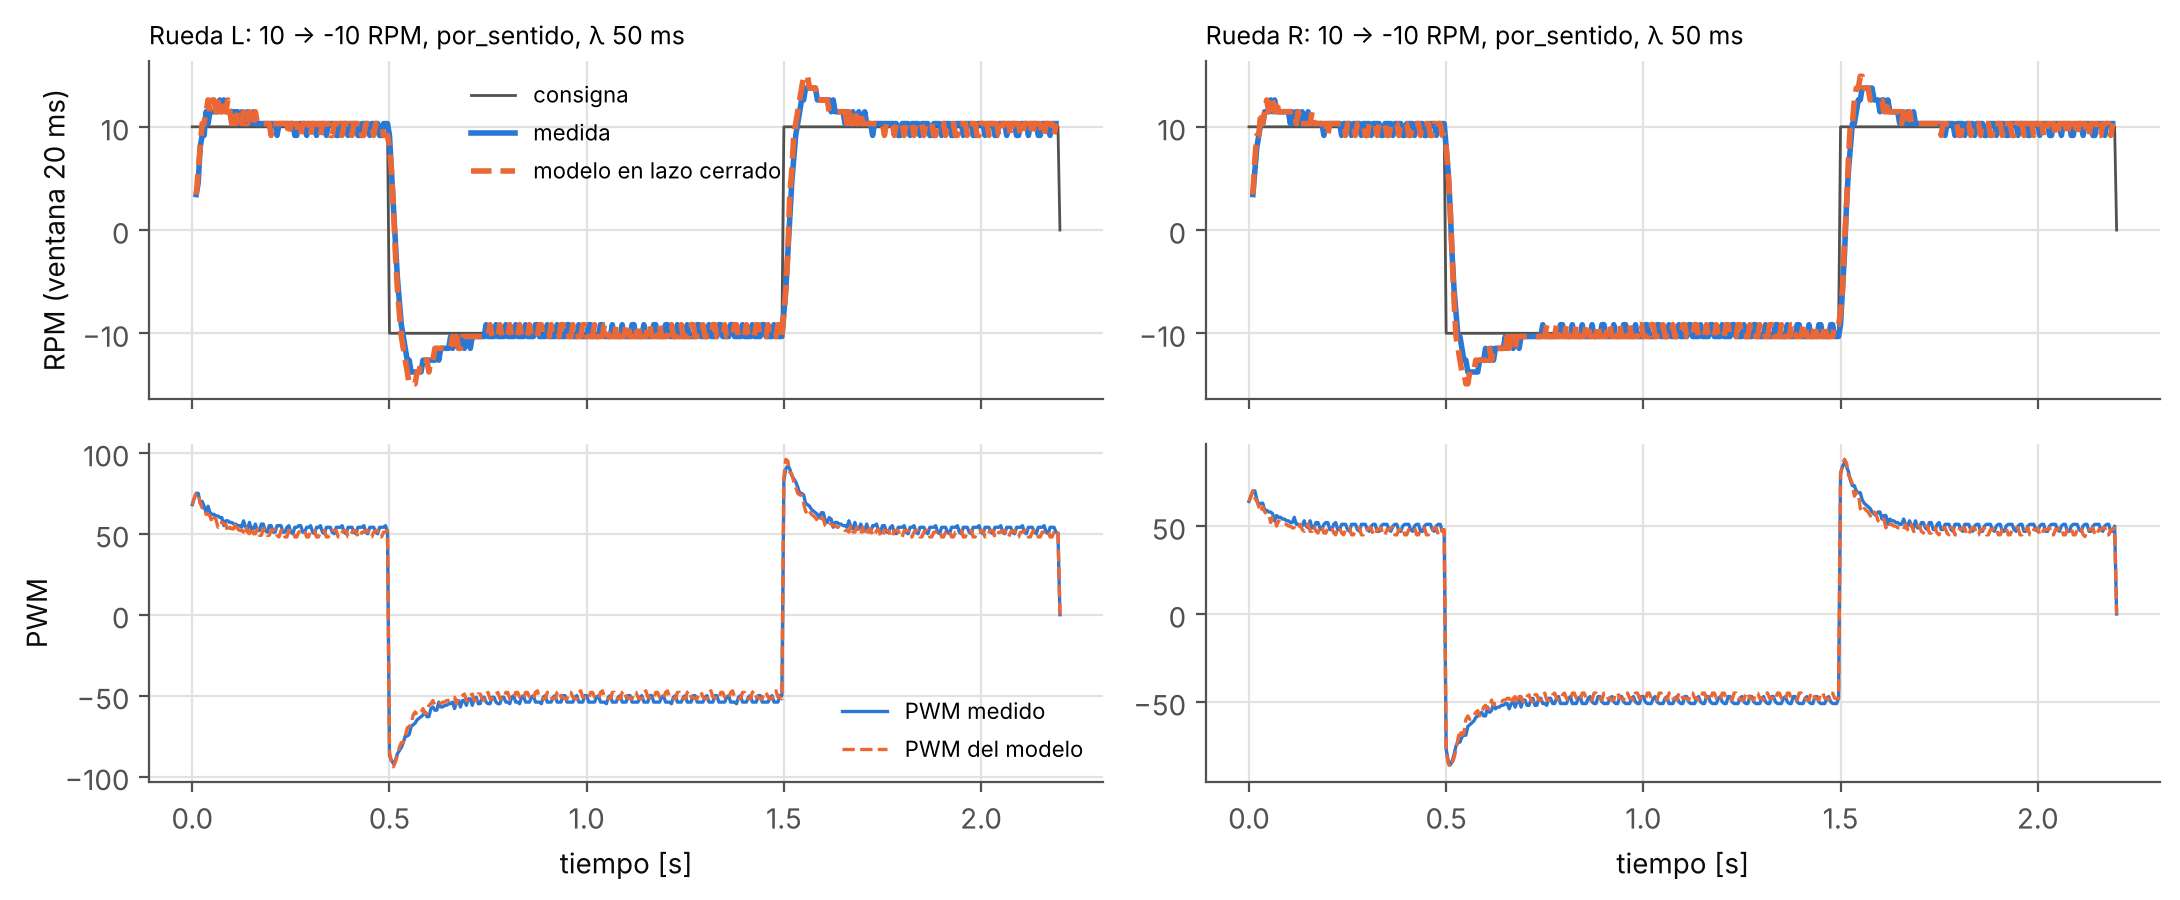

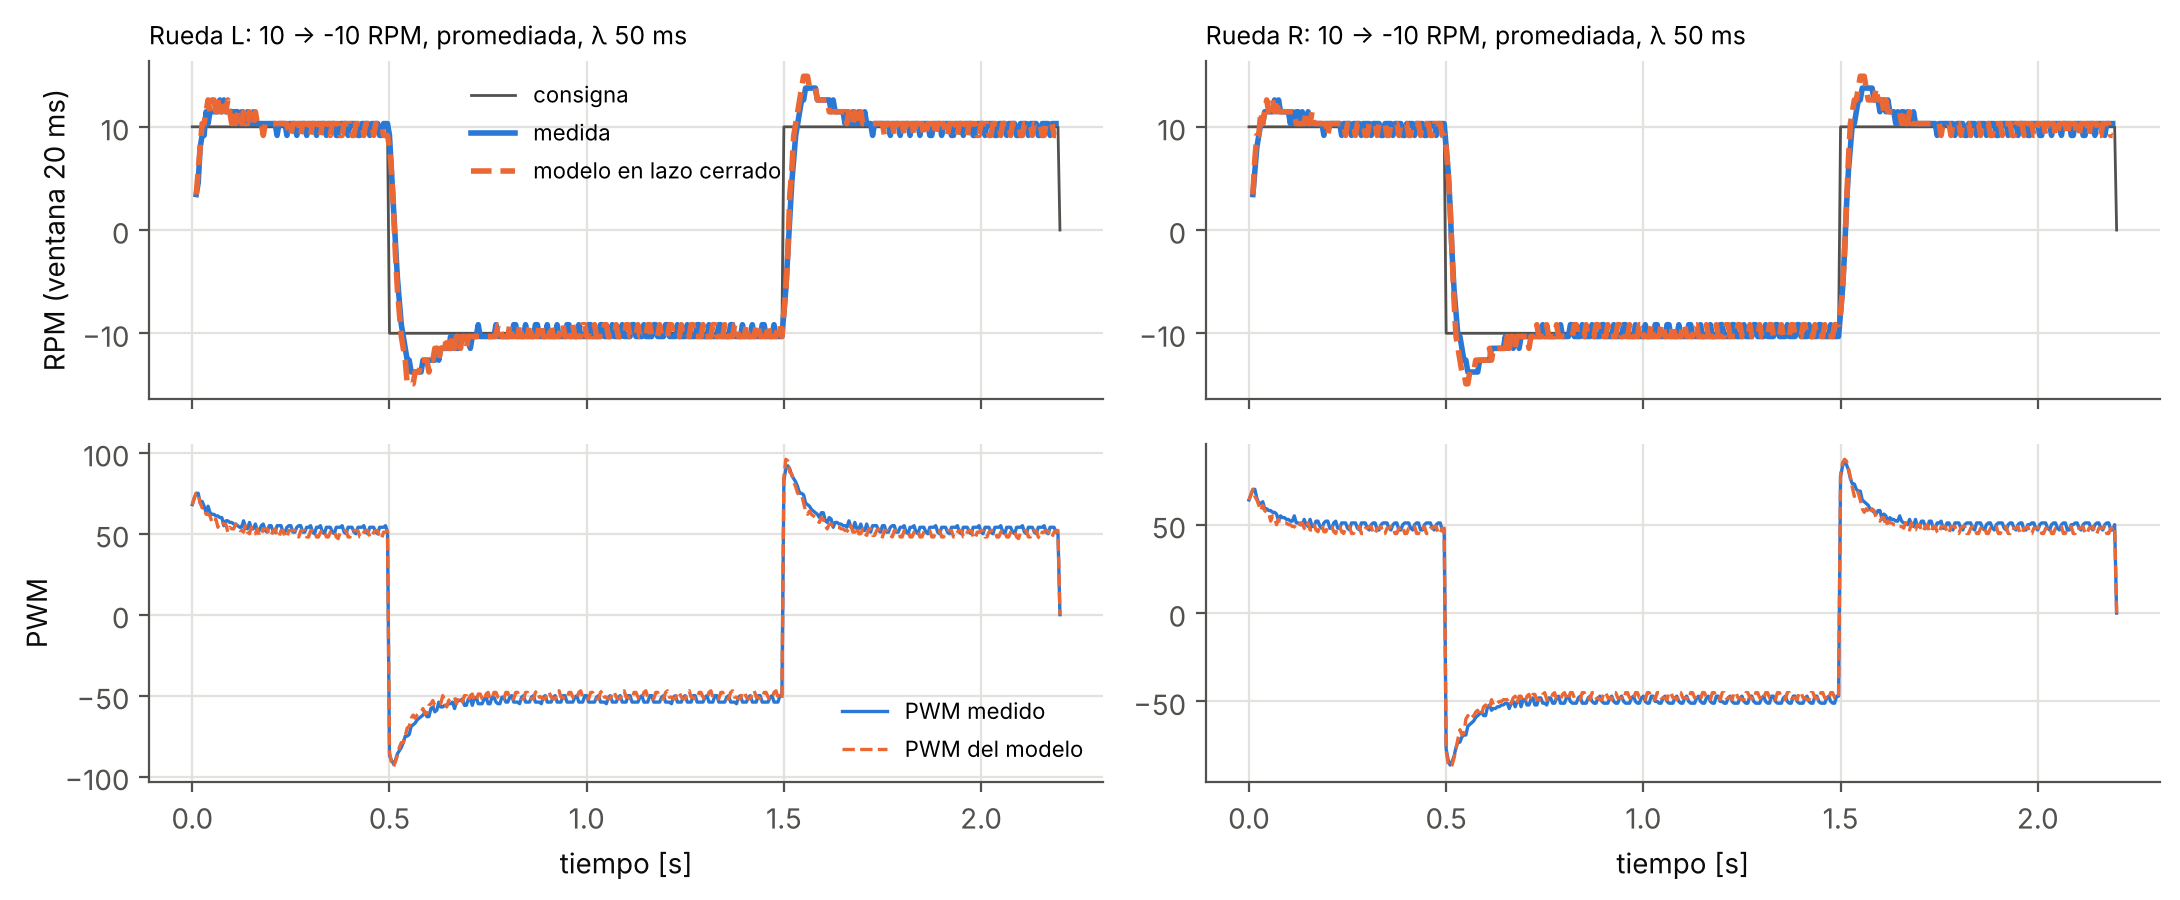

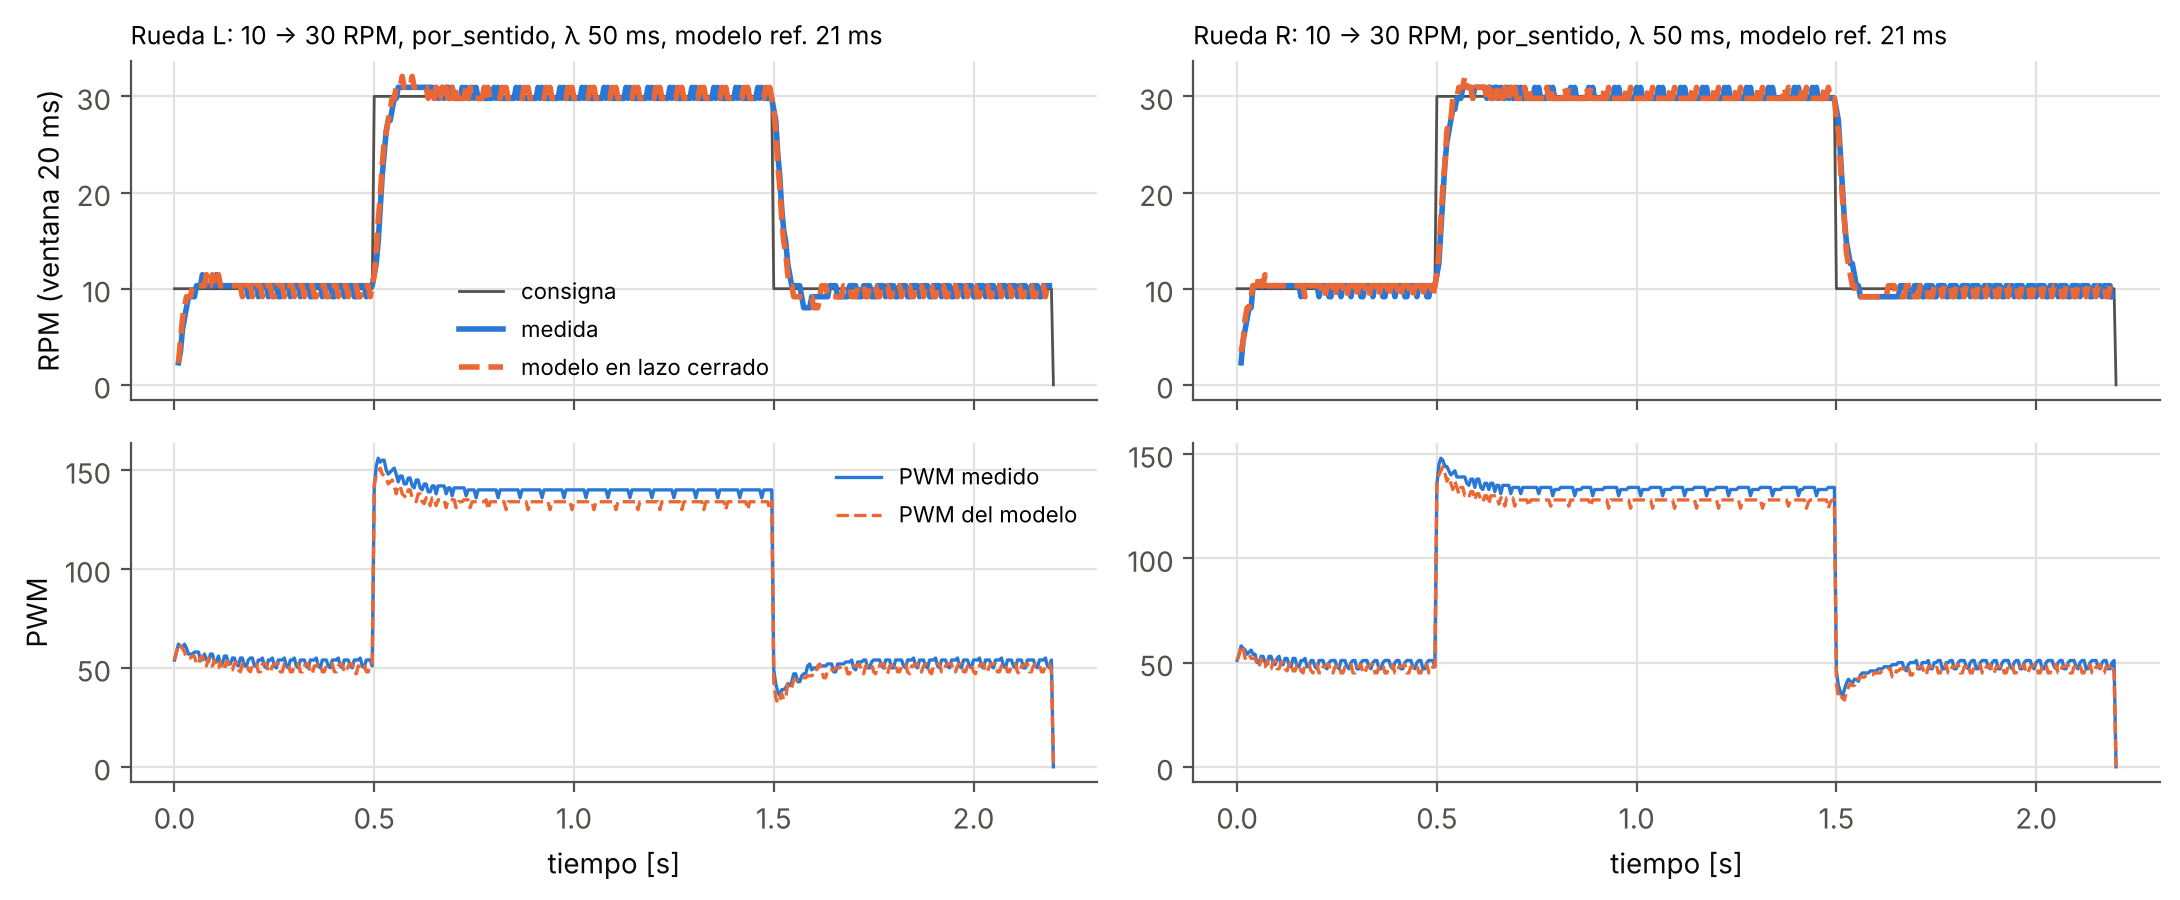

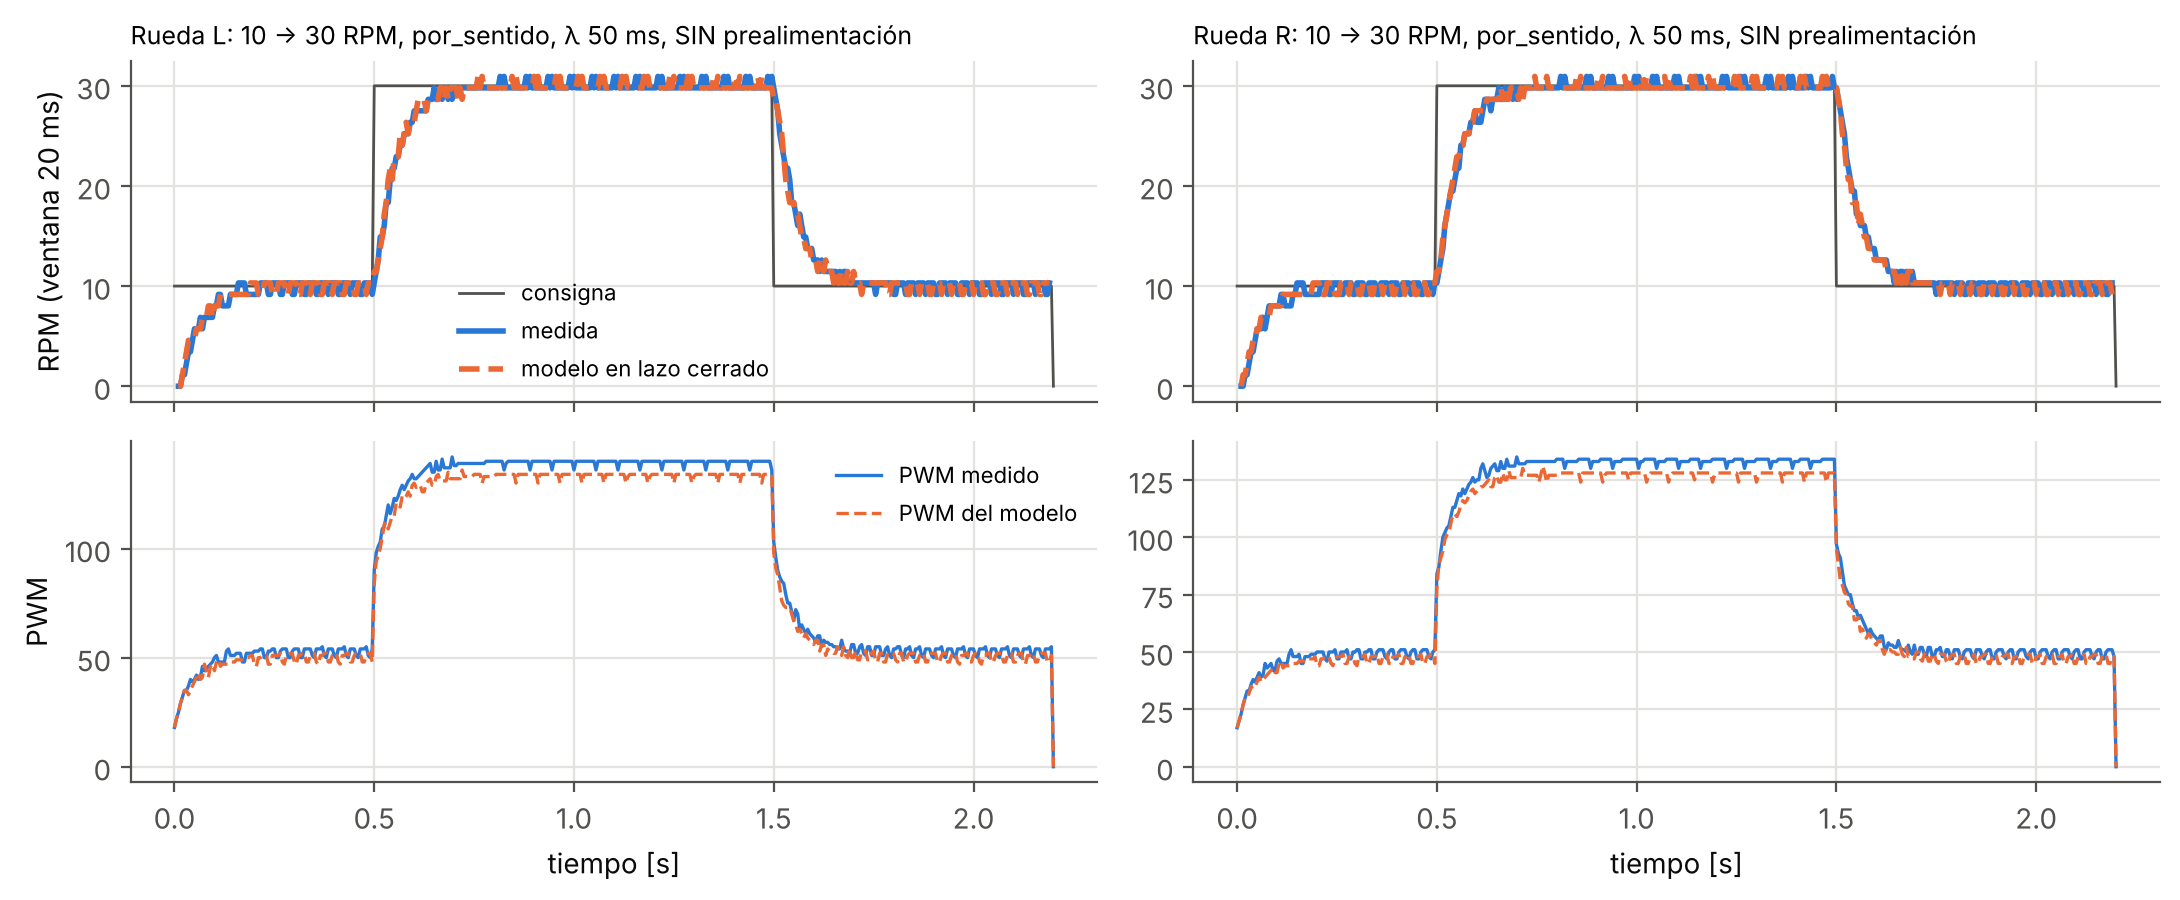

 # rueda        escalón criterio          subida [ms]    sobrepico [%]      error [RPM]
                                       medida  modelo   medida  modelo   medida  modelo
 0 L       10.0 → 30.0  por_sentido       25      20       22      22     0.01    0.00
 0 R       10.0 → 30.0  por_sentido       20      25       22      22     0.00    0.00
 1 L      -10.0 → -30.0 por_sentido       25      20       22      22    -0.00   -0.01
 1 R      -10.0 → -30.0 por_sentido       25      20       22      22    -0.00   -0.00
 2 L        0.0 → 10.0  por_sentido       20      20       26      26    -0.00   -0.00
 2 R        0.0 → 10.0  por_sentido       20      15       26      26     0.01   -0.00
 3 L       10.0 → -10.0 por_sentido       25      20       19      24     0.00    0.00
 3 R       10.0 → -10.0 por_sentido       20      20       19      24    -0.01   -0.01
 4 L       10.0 → -10.0 promediada        25      20       19      24     0.00   -0.02
 4 R       10.0 → -10.0 promediada       

In [7]:
def comparar(e, lado, ax_rpm, ax_u):
    m, meta = MODELO[lado], e["meta"]
    # Diseño del sketch frente al diseño del notebook (con el mismo λ y criterio)
    kp, ki = disenar_pi(m, meta["lambda_ms"] * 1e-3, meta["criterio"])
    kp_sk = (meta.get(f"kp_{lado}_ad"), meta.get(f"kp_{lado}_at"))
    if kp_sk[0] is not None and (abs(kp_sk[0] - kp[0]) > 0.01 * kp[0] or abs(kp_sk[1] - kp[1]) > 0.01 * kp[1]):
        print(f"  ¡Ojo! Rueda {lado}: el sketch usó Kp = {kp_sk}, el JSON da Kp = ({kp[0]:.3f}, {kp[1]:.3f}). "
              "El lazo_config.h no corresponde a este JSON.")
    consigna = e["r"][lado]
    t_sim, u_sim, c_sim = simular_lazo(m, consigna, lam=meta["lambda_ms"] * 1e-3, criterio=meta["criterio"],
                                       ff=bool(meta["ff"]), ref_tau=meta["ref_tau_ms"] * 1e-3)
    t = e["t"]
    rpm_med = rpm_de_cuentas(e["c"][lado], meta[f"cuentas_vuelta_{lado}"], ventana=0.020)
    rpm_sim = rpm_de_cuentas(c_sim, m["cpv"], ventana=0.020)
    cambios = np.flatnonzero(np.diff(consigna)) + 1
    t_ini, t_fin = t[cambios[0]], t[cambios[1]] if len(cambios) > 1 else t[-1]
    r0, r1 = consigna[0], consigna[cambios[0]]
    med, sim = metricas(t, rpm_med, r0, r1, t_ini, t_fin), metricas(t_sim, rpm_sim, r0, r1, t_ini, t_fin)
    ax_rpm.plot(t, consigna, color=GRIS, lw=1, label="consigna")
    ax_rpm.plot(t, rpm_med, color=AZUL, label="medida")
    ax_rpm.plot(t_sim, rpm_sim, color=NARANJA, ls="--", label="modelo en lazo cerrado")
    ax_u.plot(t, e["u"][lado], color=AZUL, lw=1.2, label="PWM medido")
    ax_u.plot(t_sim, u_sim, color=NARANJA, ls="--", lw=1.2, label="PWM del modelo")
    titulo = (f"Rueda {lado}: {r0:g} → {r1:g} RPM, {meta['criterio']}, λ {meta['lambda_ms']} ms"
              + (f", modelo ref. {meta['ref_tau_ms']} ms" if meta["ref_tau_ms"] else "")
              + ("" if meta["ff"] else ", SIN prealimentación"))
    ax_rpm.set_title(titulo, loc="left", fontsize=9)
    return med, sim


tabla = []
for i, e in enumerate(ensayos_lazo):
    lados = ["L", "R"] if e["meta"]["motor"] == "A" else [e["meta"]["motor"]]
    fig, ejes = plt.subplots(2, len(lados), figsize=(5.5 * len(lados), 4.6), sharex=True, squeeze=False)
    for j, lado in enumerate(lados):
        med, sim = comparar(e, lado, ejes[0, j], ejes[1, j])
        tabla.append((i, lado, e["meta"], med, sim))
        ejes[1, j].set_xlabel("tiempo [s]")
    ejes[0, 0].set_ylabel("RPM (ventana 20 ms)")
    ejes[1, 0].set_ylabel("PWM")
    ejes[0, 0].legend(loc="best", fontsize=8)
    ejes[1, 0].legend(loc="best", fontsize=8)
    plt.tight_layout()
    plt.show()

print(f"{'#':>2} {'rueda':5} {'escalón':>14} {'criterio':12} {'subida [ms]':>16} {'sobrepico [%]':>16} {'error [RPM]':>16}")
print(f"{'':>2} {'':5} {'':>14} {'':12} {'medida  modelo':>16} {'medida  modelo':>16} {'medida  modelo':>16}")
for i, lado, meta, med, sim in tabla:
    print(f"{i:>2} {lado:5} {meta['base']:>6} → {meta['escalon']:<5} {meta['criterio']:12} "
          f"{med['subida_ms']:7.0f} {sim['subida_ms']:7.0f}  {med['sobrepico_%']:7.0f} {sim['sobrepico_%']:7.0f}  "
          f"{med['error_rpm']:7.2f} {sim['error_rpm']:7.2f}")

**Qué mirar en la comparación**

| Si pasa esto | Lo más probable | Qué hacer |
|---|---|---|
| La medida sube más lento que el modelo | La batería está más baja que en el Lab 1, así que K_m real es menor | Midan la batería (`b`). El integrador corrige el error en régimen, pero la subida depende de la prealimentación |
| El PWM medido es más ruidoso que el del modelo | Ruido de medición en la ventana de 10 ms o un encoder con errores | Revisen los errores del encoder en la línea `#` |
| Hacia atrás el error es mayor con el criterio promediado | La recta de atrás no es la de adelante | Esa es la razón del criterio por sentido |
| El arranque desde 0 se queda trabado un rato | La zona muerta de arranque es mayor que N₀/K_m y el integrador tarda en llenarse | Es esperado. Compárenlo con el arranque sin prealimentación (`f 0`) |
| El modelo y la medida no se parecen en nada | El `lazo_config.h` no es el de su JSON, o los signos de `config.h` cambiaron | Revisen el aviso «¡Ojo!» arriba y repitan la prueba de sentido del Lab 1 |

## B. La rueda como fuente de velocidad

### B.1 La planta con entrada α

Con el lazo de RPM cerrado, la rueda gira a la RPM que se le pide en unos 30 ms, y el integrador corrige en régimen la carga y la batería. Para el lazo de equilibrio la entrada ya no es el par τ. La entrada pasa a ser la **aceleración angular de la rueda respecto al cuerpo**, α, que es lo que mide el encoder. Ese cambio de entrada cambia la planta.

Se parte de las ecuaciones linealizadas de la guía (paso 13):

$$A\,\ddot x + B\,\ddot\theta = \frac{\tau}{r}, \qquad C\,\ddot\theta + B\,\ddot x - B\,g\,\theta = -\tau$$

1. De la primera, $\tau = r(A\ddot x + B\ddot\theta)$. Se reemplaza en la segunda y τ desaparece: $(C + rB)\,\ddot\theta + (B + rA)\,\ddot x = B\,g\,\theta$.
2. El encoder mide el giro de la rueda **respecto al cuerpo**, $\varphi - \theta$. Entonces $\ddot x = r\,\ddot\varphi = r(\alpha + \ddot\theta)$.
3. Se reemplaza y se despeja:

$$\boxed{\ddot\theta = \frac{B\,g\,\theta - r\,(B + rA)\,\alpha}{C + 2rB + r^2A}}$$

El denominador $C + 2rB + r^2A$ es la inercia del robot respecto al **punto de contacto** con el piso. Escrito corto, $\ddot\theta = a\,\theta - b\,\alpha$, con

$$a = \frac{B\,g}{C + 2rB + r^2A}, \qquad b = \frac{r(B + rA)}{C + 2rB + r^2A}$$

**Error típico.** Uno se siente tentado a usar el péndulo invertido simple, $(\ell + r)\,\ddot\theta = g\,\theta - r\alpha$, donde $r\alpha$ es la aceleración de la rueda que mide el encoder, en m/s². Ese atajo sobreestima la gravedad. Con masa puntual, la expresión correcta es $(\ell + r)\,\ddot\theta = \frac{\ell}{\ell + r}\,g\,\theta - r\alpha$. Al atajo le falta el factor $\ell/(\ell + r)$, que en un robot como el nuestro vale más o menos 0,6. La comprobación rápida es esta: con ℓ = 0 la gravedad no puede volcar el robot, y el atajo todavía da g/r. La ecuación de arriba da 0, como debe ser. Este es un error que a mí ya me pasó en el prototipo, y por eso el robot equilibraba con una ganancia que el modelo decía que no alcanzaba.

Para la simulación se usa la versión no lineal, que sale igual pero sin linealizar:

$$\ddot\theta = \frac{B\,g\sin\theta + rB\sin\theta\,\dot\theta^2 - r(B\cos\theta + rA)\,\alpha}{C + 2rB\cos\theta + r^2A}$$

In [8]:
def estimar_Ib(M_b, alto, fondo):
    """Inercia de una caja maciza de alto × fondo respecto a su centro de masa [kg·m²]."""
    return M_b * (alto ** 2 + fondo ** 2) / 12


def constantes(geo):
    I_w = 0.5 * geo["m_w"] * geo["r"] ** 2              # disco macizo
    A = 2 * geo["m_w"] + 2 * I_w / geo["r"] ** 2 + geo["M_b"]
    B = geo["M_b"] * geo["l"]
    C = geo["I_b"] + geo["M_b"] * geo["l"] ** 2
    return A, B, C


A_, B_, C_ = constantes(GEOMETRIA)
r_ = GEOMETRIA["r"]
D_ = A_ * C_ - B_ ** 2
J0 = C_ + 2 * r_ * B_ + r_ ** 2 * A_                     # inercia respecto al punto de contacto
a = B_ * G / J0
b = r_ * (B_ + r_ * A_) / J0
p_tau = np.sqrt(A_ * B_ * G / D_)
p_alfa = np.sqrt(a)

print(f"A = {A_:.4f} kg   B = {B_:.5f} kg·m   C = {C_:.4e} kg·m²   D = {D_:.4e}")
print(f"C + 2rB + r²A = {J0:.4e} kg·m²")
print(f"a = {a:.2f} 1/s²    b = {b:.4f} (adimensional)\n")
print(f"Polo inestable con el par como entrada (paso 16): p = √(ABg/D) = {p_tau:.2f} rad/s  (1/p = {1e3/p_tau:.1f} ms)")
print(f"Polo inestable con α como entrada:               p = √a      = {p_alfa:.2f} rad/s  (1/p = {1e3/p_alfa:.1f} ms)")

A = 0.6900 kg   B = 0.04200 kg·m   C = 3.9400e-03 kg·m²   D = 9.5460e-04
C + 2rB + r²A = 7.5936e-03 kg·m²
a = 54.26 1/s²    b = 0.2931 (adimensional)

Polo inestable con el par como entrada (paso 16): p = √(ABg/D) = 17.26 rad/s  (1/p = 57.9 ms)
Polo inestable con α como entrada:               p = √a      = 7.37 rad/s  (1/p = 135.8 ms)


**Por qué cambia el polo.** Con el par como entrada y los motores sueltos, las ruedas giran libres y el robot se cae «sobre» ellas, con p = √(ABg/D). Con el lazo de RPM, la rueda no se deja mover. El robot se cae como un cuerpo que gira alrededor del punto de contacto, y por eso cae más despacio. Es el mismo robot, pero con otra entrada, y la planta que ve el controlador es otra.

Eso tiene una consecuencia práctica, y es que el periodo de muestreo del lazo de equilibrio ya no lo fija el polo de 17 rad/s. Con la rueda como fuente de velocidad, 5 ms (200 Hz) sobran.

### B.2 Espacio de estados con α

El estado es lo que el robot puede medir: θ y θ̇ con la IMU, y la velocidad y la posición de la rueda respecto al cuerpo con el encoder.

$$\mathbf{x} = \begin{bmatrix}\theta \\ \dot\theta \\ v \\ x_w\end{bmatrix}, \qquad
\dot{\mathbf{x}} = \begin{bmatrix}0 & 1 & 0 & 0\\ a & 0 & 0 & 0\\ 0 & 0 & 0 & 0\\ 0 & 0 & 1 & 0\end{bmatrix}\mathbf{x} + \begin{bmatrix}0 \\ -b \\ 1 \\ 0\end{bmatrix}\alpha$$

- v es la velocidad de la rueda respecto al cuerpo [rad/s] y $x_w$ su giro [rad]. Las dos salen del encoder.
- En el firmware, v es la **RPM deseada**. El controlador integra α para obtenerla, así que la conoce sin medirla.

La ley de control es una realimentación de los cuatro estados:

$$\alpha = k_\theta\,\theta + k_\omega\,\dot\theta + k_v\,v + k_x\,x_w$$

Se escribe con signo + para que las cuatro ganancias salgan positivas. Con la notación de los libros, $\alpha = -K\mathbf{x}$, la K tiene las mismas ganancias con signo −.

### B.3 Ubicación de polos, a mano

Con esa ley, el polinomio característico del lazo cerrado se puede sacar a mano:

$$s^4 + (b\,k_\omega - k_v)\,s^3 + (b\,k_\theta - a - k_x)\,s^2 + a\,k_v\,s + a\,k_x = 0$$

Se escogen cuatro polos, se multiplica $(s - s_1)(s - s_2)(s - s_3)(s - s_4) = s^4 + c_3s^3 + c_2s^2 + c_1s + c_0$ y se igualan coeficientes:

$$k_x = \frac{c_0}{a}, \qquad k_v = \frac{c_1}{a}, \qquad k_\theta = \frac{c_2 + a + k_x}{b}, \qquad k_\omega = \frac{c_3 + k_v}{b}$$

Lectura de diseño:

- $k_x > 0$ y $k_v > 0$. El término de velocidad va en el **mismo sentido** que la velocidad. Para frenar, el robot primero tiene que inclinarse hacia atrás, y para eso las ruedas se tienen que adelantar al cuerpo.
- $k_\theta > (a + k_x)/b$. Ese es el mínimo de la ganancia de ángulo. Con menos, la gravedad gana.
- Los dos polos rápidos manejan el equilibrio y los dos lentos la posición.

In [9]:
def ganancias(polos):
    c = np.real(np.poly(polos))            # [1, c3, c2, c1, c0]
    c3, c2, c1, c0 = c[1:]
    k_x = c0 / a
    k_v = c1 / a
    k_th = (c2 + a + k_x) / b
    k_w = (c3 + k_v) / b
    return np.array([k_th, k_w, k_v, k_x])


def ackermann(A, Bv, polos):
    """Fórmula de Ackermann: K tal que eig(A − B·K) = polos (acepta polos repetidos)."""
    n = A.shape[0]
    Wc = np.hstack([np.linalg.matrix_power(A, i) @ Bv for i in range(n)])
    phi = sum(c * np.linalg.matrix_power(A, n - i) for i, c in enumerate(np.real(np.poly(polos))))
    return (np.eye(n)[-1] @ np.linalg.inv(Wc) @ phi).ravel()


def a_firmware(k):
    """α[RPM/s] = Kθ·θ[°] + Kω·θ̇[°/s] + Kv·v[RPM] + Kx·x[vueltas]."""
    return {"Kθ [RPM/s por °]": k[0] / 6, "Kω [RPM/s por °/s]": k[1] / 6,
            "Kv [1/s]": k[2], "Kx [RPM/s por vuelta]": 60 * k[3]}


A_ss = np.array([[0, 1, 0, 0], [a, 0, 0, 0], [0, 0, 0, 0], [0, 0, 1, 0]])
B_ss = np.array([[0], [-b], [1], [0]])
k = ganancias(POLOS)
K_ack = ackermann(A_ss, B_ss, POLOS)

print("Polos deseados:", POLOS)
print("Ganancias a mano  [kθ, kω, kv, kx] =", np.round(k, 3))
print("Ackermann        −K               =", np.round(-K_ack, 3), "(deben ser iguales)")
print("Polos del lazo cerrado:", np.round(np.linalg.eigvals(A_ss + B_ss @ k[None, :]), 3))
print(f"\nMínimo de kθ: (a + kx)/b = {(a + k[3]) / b:.1f}  →  kθ = {k[0]:.1f}")
print("\nEn las unidades del firmware:")
for nombre, valor in a_firmware(k).items():
    print(f"  {nombre:24} {valor:8.2f}")

Polos deseados: [-6.0, -6.5, -1.5, -2.0]
Ganancias a mano  [kθ, kω, kv, kx] = [485.051  65.532   3.207   2.156]
Ackermann        −K               = [485.051  65.532   3.207   2.156] (deben ser iguales)
Polos del lazo cerrado: [-6.5+0.j -6. +0.j -2. +0.j -1.5+0.j]

Mínimo de kθ: (a + kx)/b = 192.5  →  kθ = 485.1

En las unidades del firmware:
  Kθ [RPM/s por °]            80.84
  Kω [RPM/s por °/s]          10.92
  Kv [1/s]                     3.21
  Kx [RPM/s por vuelta]      129.38


### B.4 Simulación con el motor como estado

La ubicación de polos supone que la rueda entrega exactamente la α que se le pide. En el robot eso no pasa por cuatro razones:

1. α se integra en la RPM deseada, que tiene tope;
2. la RPM deseada pasa por el lazo de RPM de cada rueda (parte A), con su prealimentación y su PI;
3. cada motor tiene τ, retardo, zona muerta y saturación en ±255;
4. la IMU entrega θ y θ̇ con retardo, por su filtro interno. El retardo del periodo de 5 ms ya está en la simulación, porque el controlador corre cada 5 ms y su salida se mantiene entre muestras.

Esta simulación lo incluye todo. El cuerpo sigue la ecuación no lineal de B.1. Cada rueda es el motor del Lab 1, cuyo estado es su RPM. El controlador corre cada 5 ms con la misma ley del firmware.

Hay que tener en cuenta que el motor se identificó con la rueda en el aire, así que el modelo no incluye la carga del cuerpo. En el robot, el integrador del lazo de RPM es el que la compensa.

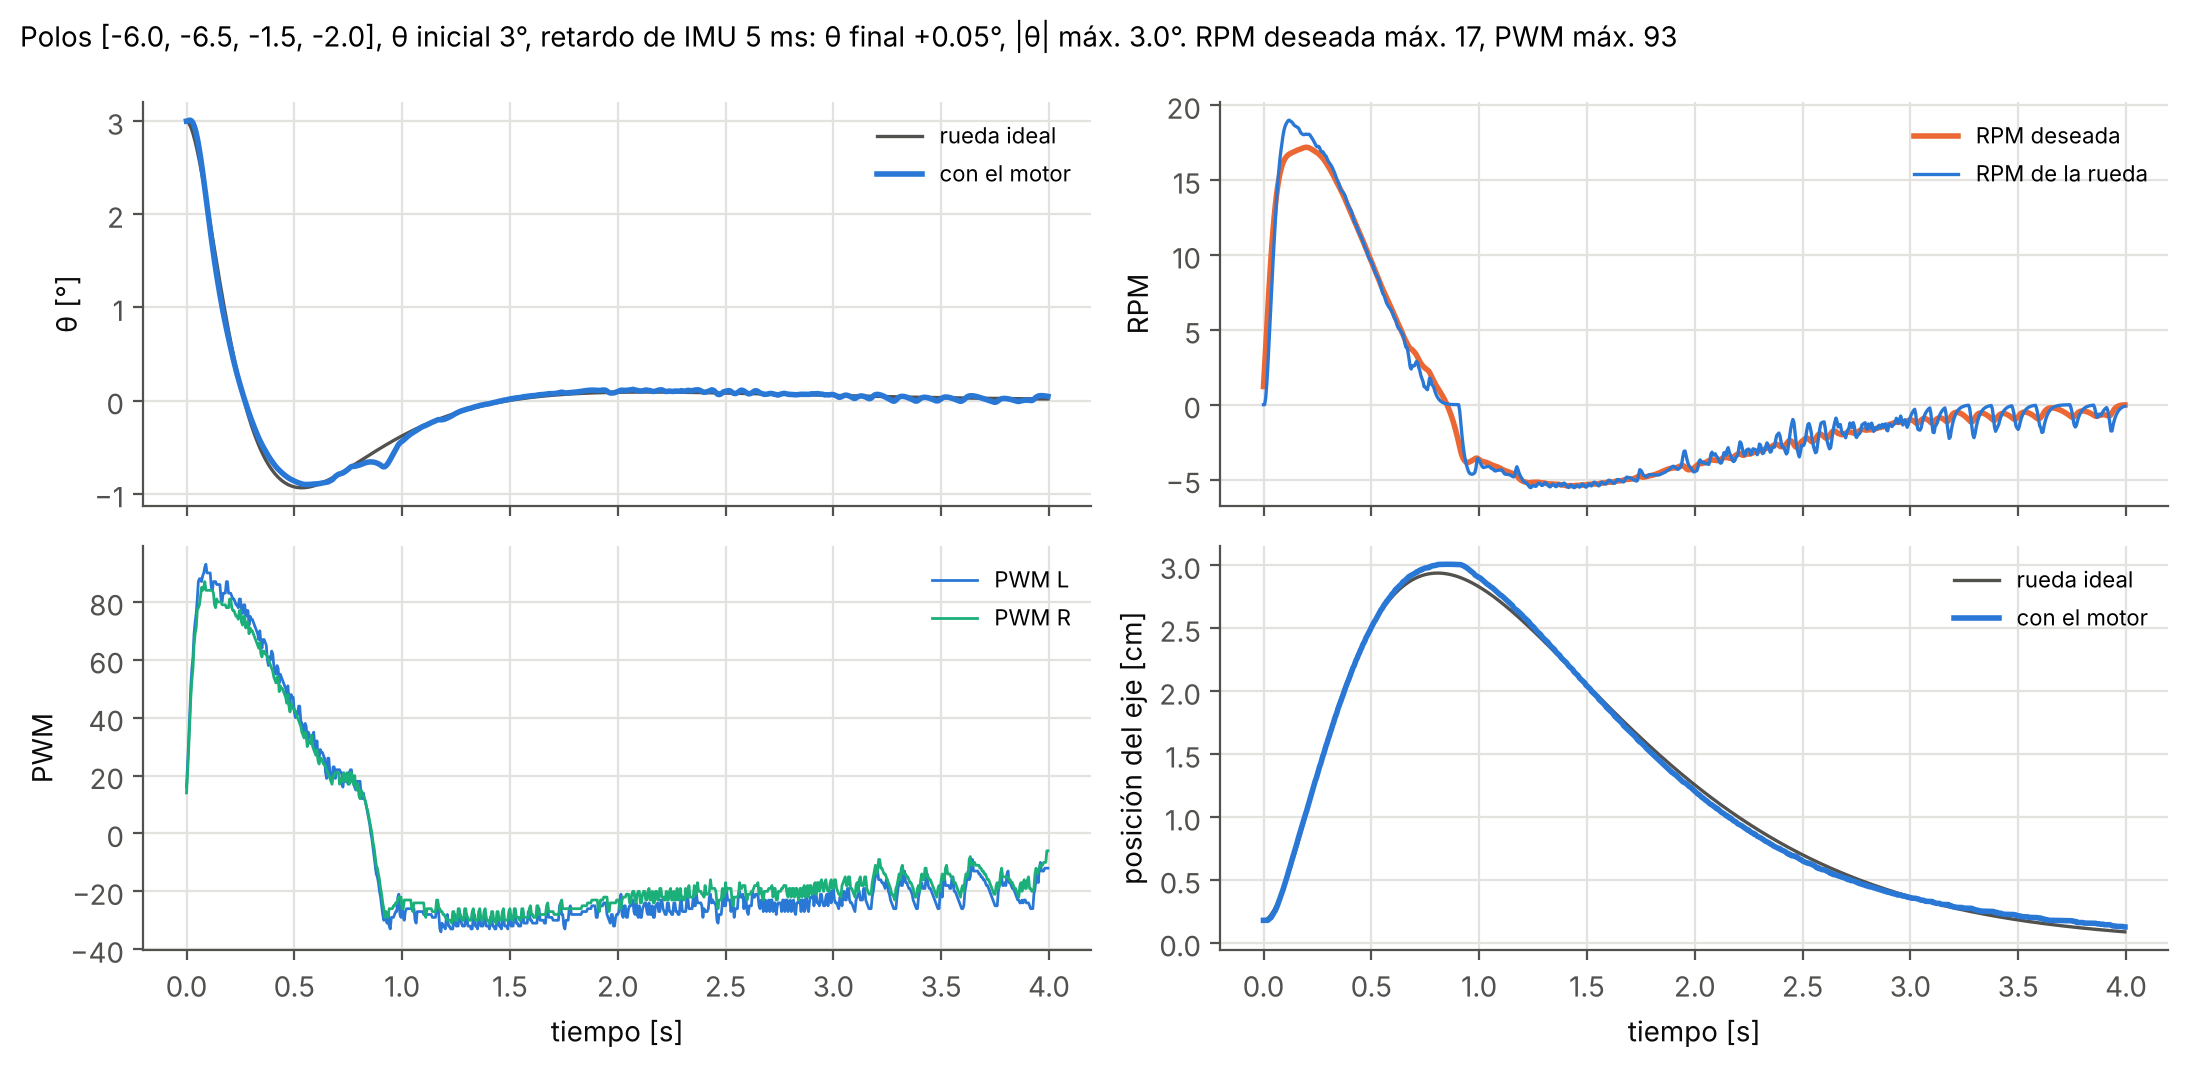

In [10]:
RETARDO_IMU = 0.005        # [s] filtro interno de la IMU (DLPF de 42 Hz ≈ 5 ms)
RPM_REF_MAX = 55.0         # tope de la RPM deseada


def simular_balancin(k, theta0_grados=3.0, T=4.0, retardo_imu=RETARDO_IMU, rueda_ideal=False, lam=LAMBDA_S):
    h = 1e-4
    n_sub, n_v = int(round(TS / h)), int(round(VENTANA / TS))
    th, dth = np.radians(theta0_grados), 0.0
    motores = {l: MotorSim(MODELO[l], h) for l in "LR"}
    lazos = {l: LazoRPM(MODELO[l], lam=lam) for l in "LR"}
    cuentas = {l: [] for l in "LR"}
    imu = deque([(th, dth)] * int(round(retardo_imu / TS)))      # atraso de N muestras
    rpm_ref, xw_ideal, v_ideal = 0.0, 0.0, 0.0
    salida = []
    for n in range(int(T / TS)):
        # --- Medición ---
        for l in "LR":
            cuentas[l].append(motores[l].cuentas())
        if rueda_ideal:
            xw = xw_ideal
        else:
            xw = np.mean([cuentas[l][-1] / MODELO[l]["cpv"] for l in "LR"]) * 2 * np.pi
        imu.append((th, dth))
        th_m, dth_m = imu.popleft()
        # --- Lazo de equilibrio: α → RPM deseada ---
        v = rpm_ref * 2 * np.pi / 60
        alfa = k[0] * th_m + k[1] * dth_m + k[2] * v + k[3] * xw                 # [rad/s²]
        rpm_ref = float(np.clip(rpm_ref + alfa * 60 / (2 * np.pi) * TS, -RPM_REF_MAX, RPM_REF_MAX))
        # --- Lazo de RPM de cada rueda ---
        u = {}
        for l in "LR":
            c = cuentas[l]
            y = (c[-1] - c[-1 - n_v]) / MODELO[l]["cpv"] / (n_v * TS) * 60 if len(c) > n_v else 0.0
            u[l] = round(lazos[l].paso(rpm_ref, y))
        rpm_med = np.mean([motores[l].rpm for l in "LR"]) if not rueda_ideal else v_ideal * 60 / (2 * np.pi)
        salida.append((n * TS, np.degrees(th), rpm_ref, rpm_med, u["L"], u["R"], 100 * r_ * (xw + th)))
        # --- Planta, cada 0,1 ms ---
        for _ in range(n_sub):
            if rueda_ideal:
                acel = (rpm_ref * 2 * np.pi / 60 - v_ideal) / 0.001          # rueda casi perfecta
                v_ideal += acel * h
                xw_ideal += v_ideal * h
            else:
                acel = np.mean([motores[l].paso(u[l]) for l in "LR"]) * 2 * np.pi / 60   # [rad/s²]
            ddth = ((B_ * G * np.sin(th) + r_ * B_ * np.sin(th) * dth ** 2 - r_ * (B_ * np.cos(th) + r_ * A_) * acel)
                    / (C_ + 2 * r_ * B_ * np.cos(th) + r_ ** 2 * A_))
            dth += ddth * h
            th += dth * h
        if abs(th) > np.radians(45):
            break
    return np.array(salida)


def graficar(sim, sim_ideal, titulo):
    fig, ejes = plt.subplots(2, 2, figsize=(11, 5.4), sharex=True)
    t = sim[:, 0]
    ejes[0, 0].plot(sim_ideal[:, 0], sim_ideal[:, 1], color=GRIS, lw=1.2, label="rueda ideal")
    ejes[0, 0].plot(t, sim[:, 1], color=AZUL, label="con el motor")
    ejes[0, 0].set_ylabel("θ [°]")
    ejes[0, 1].plot(t, sim[:, 2], color=NARANJA, label="RPM deseada")
    ejes[0, 1].plot(t, sim[:, 3], color=AZUL, lw=1.2, label="RPM de la rueda")
    ejes[0, 1].set_ylabel("RPM")
    ejes[1, 0].plot(t, sim[:, 4], color=AZUL, lw=1, label="PWM L")
    ejes[1, 0].plot(t, sim[:, 5], color=VERDE_AGUA, lw=1, label="PWM R")
    ejes[1, 0].set_ylabel("PWM")
    ejes[1, 1].plot(sim_ideal[:, 0], sim_ideal[:, 6], color=GRIS, lw=1.2, label="rueda ideal")
    ejes[1, 1].plot(t, sim[:, 6], color=AZUL, label="con el motor")
    ejes[1, 1].set_ylabel("posición del eje [cm]")
    for ax in ejes.ravel():
        ax.legend(loc="best", fontsize=8)
    for ax in ejes[1]:
        ax.set_xlabel("tiempo [s]")
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=10)
    plt.tight_layout()
    plt.show()


sim = simular_balancin(k)
sim_ideal = simular_balancin(k, rueda_ideal=True)
estado = "se cae" if sim[-1, 0] < 3.9 else f"θ final {sim[-1, 1]:+.2f}°, |θ| máx. {np.abs(sim[:, 1]).max():.1f}°"
graficar(sim, sim_ideal, f"Polos {POLOS}, θ inicial 3°, retardo de IMU {RETARDO_IMU*1e3:.0f} ms: {estado}. "
         f"RPM deseada máx. {np.abs(sim[:, 2]).max():.0f}, PWM máx. {np.abs(sim[:, 4:6]).max():.0f}")

### B.5 ¿Qué tan rápido se pueden poner los polos?

Uno pensaría que entre más rápidos los polos, mejor. Resulta que no. El retardo de la IMU y la zona muerta ponen el límite. La tabla prueba varios juegos de polos con varios retardos y da la oscilación que queda (desviación estándar de θ en el último segundo).

- Menos de 0,3° es que se sostiene quieto.
- Más de 1° es que oscila de forma sostenida.
- «Cae» es que pasó de 45°.

La celda tarda unos segundos.

In [11]:
juegos = [[-6.0, -6.5, -1.5, -2.0], [-8.0, -9.0, -2.0, -2.5], [-10.0, -11.0, -2.0, -2.5],
          [-12.0, -13.0, -2.0, -2.5], [-15.0, -16.0, -2.0, -2.5]]
retardos = [0.0, 0.005, 0.010, 0.020, 0.030]
print(f"{'polos':28} {'Kθ firmware':>12}   " + "   ".join(f"IMU {d*1e3:2.0f} ms" for d in retardos))
for polos in juegos:
    kk = ganancias(polos)
    celdas = []
    for d in retardos:
        s = simular_balancin(kk, T=5.0, retardo_imu=d)
        celdas.append("   cae   " if s[-1, 0] < 4.9 else f"{np.std(s[-200:, 1]):7.2f}° ")
    print(f"{str(polos):28} {kk[0]/6:12.1f}   " + "   ".join(celdas))

polos                         Kθ firmware   IMU  0 ms   IMU  5 ms   IMU 10 ms   IMU 20 ms   IMU 30 ms


[-6.0, -6.5, -1.5, -2.0]             80.8      0.01°       0.06°       0.04°       0.04°       0.13° 


[-8.0, -9.0, -2.0, -2.5]            121.9      0.07°       0.09°       0.08°       1.83°       2.41° 


[-10.0, -11.0, -2.0, -2.5]          155.8      0.08°       0.08°       0.09°       2.11°       2.01° 


[-12.0, -13.0, -2.0, -2.5]          194.6      0.09°       0.07°       1.32°       1.97°       2.48° 


[-15.0, -16.0, -2.0, -2.5]          262.1      0.06°       1.01°       1.40°       cae         cae   


## Preguntas de análisis

Respóndanlas con los números de **su** robot, en frases cortas.

1. ¿Cuánto vale el polo inestable de su robot con el par como entrada (paso 16) y con α como entrada? ¿Por qué el segundo es menor? ¿Qué cambia eso en el periodo de muestreo?
2. Con su geometría, ¿cuál es el mínimo de kθ? Páselo a unidades del firmware (RPM/s por grado) y compárelo con la kθ que diseñaron.
3. ¿Por qué kv y kx salen positivas? Explíquelo con lo que tiene que hacer el robot para frenar.
4. En la parte A, ¿qué tanto se parecieron la medida y el modelo en subida, sobrepico y error? Si hubo diferencia, ¿a qué la atribuyen? ¿Qué aportaron la prealimentación (ensayo B8 de la guía), el modelo de referencia (B7) y el λ de 30 ms (B6)?
5. ¿Qué pasó con el criterio promediado en el escalón hacia atrás y en el que cruza el cero? ¿Por qué?
6. De la tabla de B.5, ¿qué juego de polos escogen y por qué? ¿Qué retardo total creen que tiene su robot (IMU, filtro y periodo)?
7. En la simulación de B.4, ¿llega la RPM deseada al tope? ¿Qué inclinación inicial aguanta su diseño antes de saturar?

## Entrega del Taller 2

En el repositorio del proyecto, carpeta `taller2/`, **antes de la clase del miércoles 11 de noviembre**:

| Archivo | Contenido |
|---|---|
| `taller2_diseno.ipynb` | Este notebook ejecutado con su JSON, su geometría y sus ensayos de lazo |
| `datos_lazo/` | Los CSV o el log del sketch `lazo_rpm` |
| `lazo_config.h` | El que usaron en el robot |
| `RESPUESTAS.md` | Las respuestas a las 7 preguntas y las cuatro ganancias en unidades del firmware |